# AFS Offline Reproduction with Online-Consistent BNN

This notebook uses the existing BCLF `ext` offline Touchstone cache to train or load a BNN response surrogate with the same core settings as the BNN online experiment. It then sweeps AFS sampling counts from 4 to 20 points, reconstructs full-grid S-parameters with vector fitting, and compares Uncertainty-Aware AFS, uniform, random, and a retrospective Objective-Weighted AFS diagnostic.

The default `RUN_MODE = "smoke"` is intentionally small and CPU-safe. Change it to `"full"` to run the planned five-seed reproduction.

In [7]:
from __future__ import annotations

import hashlib
import json
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

REPO_ROOT = Path.cwd().resolve()
if not (REPO_ROOT / 'src').exists():
    for candidate in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
        if (candidate / 'src').exists() and (candidate / 'configs').exists():
            REPO_ROOT = candidate
            break
    else:
        raise RuntimeError('Cannot locate repo root from the current working directory')

for path in [REPO_ROOT, REPO_ROOT / 'src']:
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))

import afs.objective_weighted as owafs
from modeling import BCLFTouchstoneDatasetLoader, LegacyBNNResponseSurrogate, response_db
from optimization import BCLFOptimizationSpec
from paper_figures import PaperFigureExporter
from src.poles_init import basic_poles_initialize
from src.vector_fitting import evaluate, vector_fit
from src.utils import frequency_to_s

DATASET_DIR = REPO_ROOT / 'data' / 'bandpass_coupled_line_filter_export' / 'ext'
OUTPUT_DIR = REPO_ROOT / 'experiments' / 'uaw_afs_ext_offline_reproduction'
PLOT_DIR = OUTPUT_DIR / 'plots'
MODEL_DIR = OUTPUT_DIR / 'models'
PAPER_FIGURE_DIR = OUTPUT_DIR / 'paper_figures'
PAPER_ASSET_DIR = REPO_ROOT / 'docs' / 'academic' / 'paper' / 'assets' / 'uaw_afs_ext_offline_reproduction'


def relative(path: Path) -> str:
    try:
        return str(path.resolve().relative_to(REPO_ROOT))
    except ValueError:
        return str(path)


FULL_CONFIG = {
    'seeds': [0, 1, 2, 3, 4],
    'train_size': 30,
    'eval_size': 50,
    'freq_sample_size': 20,
    'hidden_dims': [256, 256, 256],
    'epochs': 800,
    'batch_size': 1024,
    'lr': 1e-3,
    'bayesian_loss_weight': 1e-4,
    'mc_samples': 64,
    'device': 'cuda',
    'target_mode': 'db',
    'vf_n_poles_real': 4,
    'vf_n_poles_complex': 8,
    'vf_max_iter': 30,
    'vf_tol': 1e-7,
    'dataset_limit': None,
    'force_retrain': False,
    'allow_bnn_training': False,
    'bnn_model_cache_csv': 'bnn_model_cache.csv',
    'reuse_sampling_sweep_cache': True,
}
SMOKE_OVERRIDES = {
    'seeds': [0],
    'train_size': 8,
    'eval_size': 5,
    'hidden_dims': [16],
    'epochs': 1,
    'batch_size': 256,
    'mc_samples': 4,
    'device': 'cpu',
    'dataset_limit': 80,
    'allow_bnn_training': True,
}
RUN_MODE = 'full'  # change to 'full' for the planned five-seed reproduction

CONFIG = dict(FULL_CONFIG)
if RUN_MODE == 'smoke':
    CONFIG.update(SMOKE_OVERRIDES)
elif RUN_MODE != 'full':
    raise ValueError("RUN_MODE must be 'smoke' or 'full'")

CONFIG


{'seeds': [0, 1, 2, 3, 4],
 'train_size': 30,
 'eval_size': 50,
 'freq_sample_size': 20,
 'hidden_dims': [256, 256, 256],
 'epochs': 800,
 'batch_size': 1024,
 'lr': 0.001,
 'bayesian_loss_weight': 0.0001,
 'mc_samples': 64,
 'device': 'cuda',
 'target_mode': 'db',
 'vf_n_poles_real': 4,
 'vf_n_poles_complex': 8,
 'vf_max_iter': 30,
 'vf_tol': 1e-07,
 'dataset_limit': None,
 'force_retrain': False,
 'allow_bnn_training': False,
 'bnn_model_cache_csv': 'bnn_model_cache.csv',
 'reuse_sampling_sweep_cache': True}

## Load Offline Ext Dataset

The loader reads `index.json` and the cached `.s2p` files directly. No worker jobs are submitted and no queue state is touched.

In [8]:
def _touchstone_frequency_signature(path: Path) -> tuple[int, float, float, float] | None:
    unit_scale = {'hz': 1.0, 'khz': 1e3, 'mhz': 1e6, 'ghz': 1e9}
    unit = 'ghz'
    freqs: list[float] = []
    with path.open('r', encoding='utf-8', errors='ignore') as fh:
        for line in fh:
            stripped = line.strip()
            if not stripped or stripped.startswith('!'):
                continue
            if stripped.startswith('#'):
                parts = stripped[1:].strip().lower().split()
                if parts and parts[0] in unit_scale:
                    unit = parts[0]
                continue
            first = stripped.split()[0]
            try:
                freqs.append(float(first) * unit_scale[unit])
            except ValueError:
                continue
    if not freqs:
        return None
    arr = np.asarray(freqs, dtype=float)
    step = float(np.median(np.diff(arr))) if len(arr) > 1 else 0.0
    return (int(len(arr)), round(float(arr[0]), 3), round(float(arr[-1]), 3), round(step, 3))


def write_filtered_ext_index() -> tuple[Path, dict]:
    source_index = DATASET_DIR / 'index.json'
    payload = json.loads(source_index.read_text(encoding='utf-8'))
    records = payload.get('records', {})
    signatures: dict[tuple[int, float, float, float] | None, list[str]] = {}
    missing_or_empty = 0
    for key, record in records.items():
        filename = str(record.get('filename', ''))
        path = DATASET_DIR / filename
        if not filename or not path.exists() or path.stat().st_size == 0:
            missing_or_empty += 1
            signatures.setdefault(None, []).append(key)
            continue
        sig = _touchstone_frequency_signature(path)
        signatures.setdefault(sig, []).append(key)

    valid_groups = {sig: keys for sig, keys in signatures.items() if sig is not None}
    if not valid_groups:
        raise ValueError(f'No compatible Touchstone records found in {DATASET_DIR}')
    dominant_sig, dominant_keys = max(valid_groups.items(), key=lambda item: len(item[1]))

    filtered_payload = dict(payload)
    filtered_payload['records'] = {key: records[key] for key in dominant_keys}
    filtered_payload['filter_metadata'] = {
        'source_index': relative(source_index),
        'dominant_frequency_signature_hz': list(dominant_sig),
        'source_records': len(records),
        'compatible_records': len(dominant_keys),
        'skipped_records': len(records) - len(dominant_keys),
        'missing_or_empty_records': missing_or_empty,
        'loaded_limit': CONFIG.get('dataset_limit'),
    }

    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    filtered_index = OUTPUT_DIR / 'filtered_ext_index.json'
    filtered_index.write_text(json.dumps(filtered_payload, indent=2), encoding='utf-8')
    return filtered_index, filtered_payload['filter_metadata']


FILTERED_INDEX_PATH, filter_metadata = write_filtered_ext_index()
loader = BCLFTouchstoneDatasetLoader(
    dataset_dir=DATASET_DIR,
    index_filename=str(FILTERED_INDEX_PATH),
)
dataset = loader.load(limit=CONFIG.get('dataset_limit'))

assert dataset.n_samples > 0
assert dataset.n_freqs == dataset.s_params.shape[-1]
assert dataset.s_params.shape[1:3] == (2, 2)
assert np.all(np.isfinite(dataset.freqs))
assert np.iscomplexobj(dataset.s_params)

freqs_ghz = dataset.freqs / 1e9
dataset_summary = {
    'loaded_samples': dataset.n_samples,
    'compatible_records': int(filter_metadata['compatible_records']),
    'skipped_records': int(filter_metadata['skipped_records']),
    'load_limit': CONFIG.get('dataset_limit'),
    'frequency_points': dataset.n_freqs,
    'frequency_min_ghz': float(freqs_ghz.min()),
    'frequency_max_ghz': float(freqs_ghz.max()),
    'variables': dataset.variable_order,
}
dataset_summary

{'loaded_samples': 1369,
 'compatible_records': 1369,
 'skipped_records': 7,
 'load_limit': None,
 'frequency_points': 401,
 'frequency_min_ghz': 3.5,
 'frequency_max_ghz': 8.7,
 'variables': ['L', 'L1', 'L2', 'W', 'W1', 'W2', 'S1', 'S2']}

## BCLF Objective And Reconstruction Helpers

In [9]:
SPEC = BCLFOptimizationSpec(
    passband_ghz=(4.8, 5.4),
    lower_stopband_ghz=(3.6, 4.4),
    upper_stopband_ghz=(5.8, 8.7),
    min_passband_s21_db=-5.0,
    max_passband_s11_db=-7.0,
    max_stopband_s21_db=-15.0,
    s11_weight=0.5,
    stopband_weight=0.5,
)


def channel_db(s_params: np.ndarray, row: int, col: int) -> np.ndarray:
    arr = np.asarray(s_params)
    if arr.ndim == 3:
        return response_db(arr[None, ...], row, col)[0]
    return response_db(arr, row, col)


def objective_value(s_params: np.ndarray) -> float:
    return float(SPEC.evaluate(dataset.freqs, s_params).scalar_objective())


def objective_abs_error(true_s: np.ndarray, pred_s: np.ndarray) -> float:
    return float(abs(objective_value(true_s) - objective_value(pred_s)))


def db_error_metrics(true_s: np.ndarray, pred_s: np.ndarray, row: int, col: int) -> dict[str, float]:
    err = channel_db(pred_s, row, col) - channel_db(true_s, row, col)
    return {
        'mae': float(np.mean(np.abs(err))),
        'rmse': float(np.sqrt(np.mean(err ** 2))),
        'max': float(np.max(np.abs(err))),
    }


def select_frequency_indices(method: str, uncertainty_profile: np.ndarray, n_points: int, rng: np.random.Generator) -> np.ndarray:
    n_freqs = len(dataset.freqs)
    if n_points > n_freqs:
        raise ValueError('freq_sample_size exceeds available frequencies')
    if n_points <= 2:
        return np.linspace(0, n_freqs - 1, n_points, dtype=int)

    interior = np.arange(1, n_freqs - 1, dtype=int)
    need = n_points - 2
    if method == 'uniform':
        selected = np.linspace(1, n_freqs - 2, need, dtype=float)
        interior_idx = np.unique(np.round(selected).astype(int))
        while len(interior_idx) < need:
            missing = np.setdiff1d(interior, interior_idx, assume_unique=False)
            interior_idx = np.sort(np.append(interior_idx, missing[: need - len(interior_idx)]))
    elif method == 'random':
        interior_idx = np.sort(rng.choice(interior, size=need, replace=False))
    elif method == 'uaw':
        u = np.asarray(uncertainty_profile, dtype=float).reshape(-1)
        u = np.maximum(u, 0.0)
        weights = u[interior]
        if not np.isfinite(weights).all() or float(weights.sum()) <= 0.0:
            weights = np.ones_like(weights, dtype=float)
        else:
            uniform_floor = 0.1 * np.ones_like(weights, dtype=float) / len(weights)
            weights = uniform_floor + 0.9 * weights / float(weights.sum())
        interior_idx = np.sort(rng.choice(interior, size=need, replace=False, p=weights / weights.sum()))
    else:
        raise ValueError(f'unknown method: {method}')
    return np.asarray([0, *interior_idx.tolist(), n_freqs - 1], dtype=int)


VF_ORDER_POLICY_FIXED = 'fixed'
VF_ORDER_POLICY_ORDER_MATCHED = 'pole_residue_budget'


def vf_order_for_sample_count(sample_count: int, policy: str = VF_ORDER_POLICY_FIXED) -> dict[str, int | str]:
    sample_count = int(sample_count)
    if sample_count < 1:
        raise ValueError('sample_count must be positive')

    if policy == VF_ORDER_POLICY_FIXED:
        n_real = int(CONFIG['vf_n_poles_real'])
        n_complex = int(CONFIG['vf_n_poles_complex'])
    elif policy == VF_ORDER_POLICY_ORDER_MATCHED:
        actual_poles = max(1, sample_count // 2)
        n_complex = actual_poles // 2
        n_real = actual_poles % 2
    else:
        raise ValueError(f'unknown VF order policy: {policy}')

    actual_poles = int(n_real + 2 * n_complex)
    return {
        'vf_order_policy': str(policy),
        'vf_actual_poles': actual_poles,
        'vf_n_poles_real': int(n_real),
        'vf_n_poles_complex': int(n_complex),
        'vf_pole_residue_terms': int(2 * actual_poles),
    }


def fit_channel_from_indices(
    s_params: np.ndarray,
    indices: np.ndarray,
    row: int,
    col: int,
    *,
    vf_order_policy: str = VF_ORDER_POLICY_FIXED,
) -> np.ndarray:
    order = vf_order_for_sample_count(len(indices), vf_order_policy)
    init_poles = basic_poles_initialize(
        freqs_range=(float(dataset.freqs[0]), float(dataset.freqs[-1])),
        n_poles_real=int(order['vf_n_poles_real']),
        n_poles_complex=int(order['vf_n_poles_complex']),
    )
    poles, residues, d, h = vector_fit(
        dataset.freqs[indices],
        s_params[row, col, indices],
        init_poles=init_poles,
        max_iter=int(CONFIG['vf_max_iter']),
        tol=float(CONFIG['vf_tol']),
        atol=float(CONFIG['vf_tol']),
        rtol=float(CONFIG['vf_tol']),
    )
    return evaluate(poles, residues, d, h, frequency_to_s(dataset.freqs))


def reconstruct_sparams(
    s_params: np.ndarray,
    indices: np.ndarray,
    *,
    vf_order_policy: str = VF_ORDER_POLICY_FIXED,
) -> np.ndarray:
    pred = np.zeros_like(s_params, dtype=complex)
    pred[0, 0, :] = fit_channel_from_indices(s_params, indices, 0, 0, vf_order_policy=vf_order_policy)
    pred[0, 1, :] = fit_channel_from_indices(s_params, indices, 0, 1, vf_order_policy=vf_order_policy)
    # BCLF is treated as reciprocal/symmetric for this AFS reproduction path.
    pred[1, 0, :] = pred[0, 1, :]
    pred[1, 1, :] = pred[0, 0, :]
    return pred


BCLF_BOUNDARY_GHZ = np.asarray([3.6, 4.4, 4.8, 5.4, 5.8], dtype=float)
ORACLE_INITIAL_ANCHOR_COUNT = 9


def nearest_frequency_index(freq_ghz: float) -> int:
    return int(np.argmin(np.abs(freqs_ghz - float(freq_ghz))))


def unique_preserving_order(values: list[int]) -> list[int]:
    seen: set[int] = set()
    out: list[int] = []
    for value in values:
        value = int(value)
        if value not in seen:
            seen.add(value)
            out.append(value)
    return out


def uniform_fill_indices(n_points: int) -> list[int]:
    return [int(i) for i in np.round(np.linspace(0, dataset.n_freqs - 1, int(n_points))).astype(int)]


def oracle_anchor_indices(n_points: int) -> np.ndarray:
    anchor_count = min(int(n_points), ORACLE_INITIAL_ANCHOR_COUNT)
    priority = unique_preserving_order(
        [0, dataset.n_freqs - 1]
        + [nearest_frequency_index(freq_ghz) for freq_ghz in BCLF_BOUNDARY_GHZ]
        + uniform_fill_indices(max(anchor_count, 2))
    )
    selected = priority[:anchor_count]
    if len(selected) < anchor_count:
        for idx in uniform_fill_indices(dataset.n_freqs):
            if idx not in selected:
                selected.append(idx)
            if len(selected) == anchor_count:
                break
    return np.asarray(sorted(selected), dtype=int)


def oracle_band_weights() -> np.ndarray:
    weights = np.ones(dataset.n_freqs, dtype=float)
    passband = (freqs_ghz >= 4.8) & (freqs_ghz <= 5.4)
    low_stop = (freqs_ghz >= 3.6) & (freqs_ghz <= 4.4)
    high_stop = (freqs_ghz >= 5.8) & (freqs_ghz <= 8.7)
    weights[passband] = np.maximum(weights[passband], 1.5)
    weights[low_stop | high_stop] = np.maximum(weights[low_stop | high_stop], 1.25)
    for freq_ghz in BCLF_BOUNDARY_GHZ:
        center = nearest_frequency_index(float(freq_ghz))
        lo = max(0, center - 2)
        hi = min(dataset.n_freqs, center + 3)
        weights[lo:hi] = np.maximum(weights[lo:hi], 2.0)
    return weights


ORACLE_BAND_WEIGHTS = None


def oracle_weighted_vf_error(true_s: np.ndarray, pred_s: np.ndarray) -> np.ndarray:
    global ORACLE_BAND_WEIGHTS
    if ORACLE_BAND_WEIGHTS is None:
        ORACLE_BAND_WEIGHTS = oracle_band_weights()
    s11_err = np.abs(channel_db(true_s, 0, 0) - channel_db(pred_s, 0, 0))
    s21_err = np.abs(channel_db(true_s, 0, 1) - channel_db(pred_s, 0, 1))
    return ORACLE_BAND_WEIGHTS * (0.5 * s11_err + 1.0 * s21_err)


def select_oracle_vf_error_indices(
    true_s: np.ndarray,
    n_points: int,
    *,
    min_spacing: int = 2,
    vf_order_policy: str = VF_ORDER_POLICY_FIXED,
) -> np.ndarray:
    n_points = int(n_points)
    if n_points > dataset.n_freqs:
        raise ValueError('freq_sample_size exceeds available frequencies')
    indices = oracle_anchor_indices(n_points)
    if len(indices) >= n_points:
        return np.asarray(sorted(indices[:n_points]), dtype=int)

    selected = set(int(i) for i in indices)
    while len(selected) < n_points:
        current = np.asarray(sorted(selected), dtype=int)
        pred_s = reconstruct_sparams(true_s, current, vf_order_policy=vf_order_policy)
        score = oracle_weighted_vf_error(true_s, pred_s)
        unsampled = np.asarray([idx for idx in range(dataset.n_freqs) if idx not in selected], dtype=int)
        if unsampled.size == 0:
            break
        distances = np.min(np.abs(unsampled[:, None] - current[None, :]), axis=1)
        candidates = unsampled[distances >= int(min_spacing)]
        if candidates.size == 0:
            candidates = unsampled
        next_idx = int(candidates[np.argmax(score[candidates])])
        selected.add(next_idx)
    return np.asarray(sorted(selected), dtype=int)


def select_oracle_vf_error_index_path(
    true_s: np.ndarray,
    sample_counts: list[int] | tuple[int, ...],
    *,
    min_spacing: int = 2,
    vf_order_policy: str = VF_ORDER_POLICY_FIXED,
) -> dict[int, np.ndarray]:
    counts = sorted({int(n) for n in sample_counts})
    if not counts:
        return {}
    if counts[-1] > dataset.n_freqs:
        raise ValueError('freq_sample_size exceeds available frequencies')

    out: dict[int, np.ndarray] = {}
    anchor_limit = min(counts[-1], ORACLE_INITIAL_ANCHOR_COUNT)
    for n_points in counts:
        if n_points <= anchor_limit:
            out[n_points] = oracle_anchor_indices(n_points)

    selected = set(int(i) for i in oracle_anchor_indices(anchor_limit))
    if anchor_limit in counts:
        out[anchor_limit] = np.asarray(sorted(selected), dtype=int)

    target_counts = set(counts)
    while len(selected) < counts[-1]:
        current = np.asarray(sorted(selected), dtype=int)
        pred_s = reconstruct_sparams(true_s, current, vf_order_policy=vf_order_policy)
        score = oracle_weighted_vf_error(true_s, pred_s)
        unsampled = np.asarray([idx for idx in range(dataset.n_freqs) if idx not in selected], dtype=int)
        if unsampled.size == 0:
            break
        distances = np.min(np.abs(unsampled[:, None] - current[None, :]), axis=1)
        candidates = unsampled[distances >= int(min_spacing)]
        if candidates.size == 0:
            candidates = unsampled
        selected.add(int(candidates[np.argmax(score[candidates])]))
        if len(selected) in target_counts:
            out[len(selected)] = np.asarray(sorted(selected), dtype=int)
    return out


def uncertainty_profile_from_samples(response_samples: np.ndarray, local_pos: int) -> np.ndarray:
    s11 = response_db(response_samples[:, local_pos:local_pos + 1], 0, 0)[:, 0, :]
    s21 = response_db(response_samples[:, local_pos:local_pos + 1], 0, 1)[:, 0, :]
    return np.var(s11, axis=0) + np.var(s21, axis=0)


def method_rng(seed: int, sample_idx: int, method: str) -> np.random.Generator:
    method_offset = METHODS.index(method)
    return np.random.default_rng(seed * 100_000 + int(sample_idx) * 10 + method_offset)

## Section 1 - Train Or Load BNN Models

This section creates deterministic train/eval splits for each seed. In full mode it first reuses the existing `bnn_model_cache.csv` manifest so rerunning the notebook does not retrain BNNs when the `ext` cache grows. Exact cache lookup is used as a fallback. New BNN training only happens when `allow_bnn_training=True`.

In [10]:
def write_run_config(config: dict) -> None:
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    PLOT_DIR.mkdir(parents=True, exist_ok=True)
    MODEL_DIR.mkdir(parents=True, exist_ok=True)
    saved_config = {
        'run_mode': RUN_MODE,
        'dataset_dir': relative(DATASET_DIR),
        'output_dir': relative(OUTPUT_DIR),
        'model_dir': relative(MODEL_DIR),
        'dataset_summary': dataset_summary,
        **config,
    }
    (OUTPUT_DIR / 'run_config.json').write_text(json.dumps(saved_config, indent=2), encoding='utf-8')


def split_indices_for_seed(seed: int, config: dict) -> tuple[np.ndarray, np.ndarray]:
    total_needed = int(config['train_size']) + int(config['eval_size'])
    if total_needed > dataset.n_samples:
        raise ValueError(f'train_size + eval_size = {total_needed} exceeds dataset size {dataset.n_samples}')
    rng = np.random.default_rng(int(seed))
    order = rng.permutation(dataset.n_samples)
    train_idx = np.sort(order[: int(config['train_size'])])
    eval_idx = np.sort(order[int(config['train_size']): total_needed])
    return train_idx, eval_idx


def bnn_training_config(config: dict) -> dict:
    return {
        'hidden_dims': list(config['hidden_dims']),
        'epochs': int(config['epochs']),
        'batch_size': int(config['batch_size']),
        'lr': float(config['lr']),
        'bayesian_loss_weight': float(config['bayesian_loss_weight']),
        'target_mode': str(config['target_mode']),
    }


def model_cache_payload(seed: int, train_idx: np.ndarray, config: dict) -> dict:
    return {
        'seed': int(seed),
        'training_config': bnn_training_config(config),
        'dataset': {
            'frequency_points': int(dataset.n_freqs),
            'frequency_min_hz': float(dataset.freqs[0]),
            'frequency_max_hz': float(dataset.freqs[-1]),
            'loaded_samples': int(dataset.n_samples),
            'compatible_records': int(dataset_summary['compatible_records']),
        },
        'train_idx': [int(i) for i in train_idx],
        'train_case_ids': [dataset.case_ids[int(i)] for i in train_idx],
    }


def model_cache_paths(seed: int, train_idx: np.ndarray, config: dict) -> tuple[Path, Path, dict]:
    payload = model_cache_payload(seed, train_idx, config)
    digest = hashlib.sha256(json.dumps(payload, sort_keys=True).encode('utf-8')).hexdigest()[:12]
    stem = f"bnn_seed{int(seed)}_{digest}"
    return MODEL_DIR / f'{stem}.pt', MODEL_DIR / f'{stem}.json', payload


def build_bnn_surrogate(seed: int, config: dict) -> LegacyBNNResponseSurrogate:
    return LegacyBNNResponseSurrogate(
        hidden_dims=list(config['hidden_dims']),
        epochs=int(config['epochs']),
        batch_size=int(config['batch_size']),
        lr=float(config['lr']),
        bayesian_loss_weight=float(config['bayesian_loss_weight']),
        mc_samples=int(config['mc_samples']),
        target_mode=str(config['target_mode']),
        seed=int(seed),
        device=str(config['device']),
    )


def resolve_repo_path(value: str | Path) -> Path:
    path = Path(str(value))
    return path if path.is_absolute() else REPO_ROOT / path


def parse_index_list(value) -> np.ndarray:
    if value is None or (isinstance(value, float) and pd.isna(value)):
        return np.asarray([], dtype=int)
    text = str(value).strip()
    if not text:
        return np.asarray([], dtype=int)
    return np.asarray([int(part) for part in text.split(';') if part.strip()], dtype=int)


def bnn_manifest_path(config: dict) -> Path | None:
    raw = str(config.get('bnn_model_cache_csv', '')).strip()
    if not raw:
        return None
    path = Path(raw)
    return path if path.is_absolute() else OUTPUT_DIR / path


def load_manifest_bnn_state(seed: int, config: dict) -> dict | None:
    if bool(config.get('force_retrain', False)):
        return None
    manifest_path = bnn_manifest_path(config)
    if manifest_path is None or not manifest_path.exists():
        return None
    manifest = pd.read_csv(manifest_path)
    if 'seed' not in manifest.columns:
        return None
    rows = manifest[manifest['seed'].astype(int) == int(seed)]
    if rows.empty:
        return None
    row = rows.iloc[0]
    model_path = resolve_repo_path(row['model_path'])
    metadata_path = resolve_repo_path(row['metadata_path'])
    if not model_path.exists() or not metadata_path.exists():
        return None
    metadata = json.loads(metadata_path.read_text(encoding='utf-8'))
    payload = metadata.get('cache_payload', {})
    if payload.get('training_config') != bnn_training_config(config):
        return None
    train_idx = np.asarray(payload.get('train_idx', []), dtype=int)
    eval_idx = parse_index_list(row.get('eval_idx', ''))
    if train_idx.size != int(config['train_size']) or eval_idx.size != int(config['eval_size']):
        return None
    if train_idx.size and int(train_idx.max()) >= dataset.n_samples:
        return None
    if eval_idx.size and int(eval_idx.max()) >= dataset.n_samples:
        return None
    surrogate = LegacyBNNResponseSurrogate.load(model_path, device=str(config['device']))
    return {
        'seed': int(seed),
        'surrogate': surrogate,
        'train_idx': train_idx,
        'eval_idx': eval_idx,
        'model_status': 'loaded',
        'cache_source': 'manifest',
        'model_path': relative(model_path),
        'metadata_path': relative(metadata_path),
        'train_sec': 0.0,
        'cached_train_sec': float(metadata.get('train_sec', 0.0)),
        'train_size': int(train_idx.size),
    }


def train_or_load_bnn(seed: int, train_idx: np.ndarray, config: dict) -> tuple[LegacyBNNResponseSurrogate, dict]:
    model_path, metadata_path, payload = model_cache_paths(seed, train_idx, config)
    can_load = bool(model_path.exists() and metadata_path.exists() and not config.get('force_retrain', False))
    if can_load:
        metadata = json.loads(metadata_path.read_text(encoding='utf-8'))
        if metadata.get('cache_payload') == payload:
            surrogate = LegacyBNNResponseSurrogate.load(model_path, device=str(config['device']))
            return surrogate, {
                'seed': int(seed),
                'model_status': 'loaded',
                'model_path': relative(model_path),
                'metadata_path': relative(metadata_path),
                'train_sec': 0.0,
                'cache_source': 'exact',
                'train_size': int(len(train_idx)),
            }

    if not bool(config.get('allow_bnn_training', True)):
        raise FileNotFoundError(
            f'No cached BNN model for seed={seed}. '
            'Set allow_bnn_training=True to train a new model, or restore/update bnn_model_cache.csv.'
        )

    surrogate = build_bnn_surrogate(seed, config)
    t0 = time.perf_counter()
    surrogate.fit(dataset, train_idx, epochs=int(config['epochs']))
    train_sec = float(time.perf_counter() - t0)
    surrogate.save(model_path, metadata={'cache_payload': payload})
    metadata_path.write_text(
        json.dumps(
            {
                'cache_payload': payload,
                'model_path': relative(model_path),
                'train_sec': train_sec,
            },
            indent=2,
        ),
        encoding='utf-8',
    )
    return surrogate, {
        'seed': int(seed),
        'model_status': 'trained',
        'model_path': relative(model_path),
        'metadata_path': relative(metadata_path),
        'train_sec': train_sec,
        'cache_source': 'trained',
        'train_size': int(len(train_idx)),
    }


def prepare_bnn_models(config: dict) -> tuple[dict[int, dict], pd.DataFrame]:
    write_run_config(config)
    states: dict[int, dict] = {}
    rows: list[dict] = []
    for seed in config['seeds']:
        seed = int(seed)
        state = load_manifest_bnn_state(seed, config)
        if state is None:
            train_idx, eval_idx = split_indices_for_seed(seed, config)
            surrogate, record = train_or_load_bnn(seed, train_idx, config)
            state = {
                'seed': seed,
                'surrogate': surrogate,
                'train_idx': train_idx,
                'eval_idx': eval_idx,
                **record,
            }
        states[seed] = state
        rows.append({
            'seed': int(state['seed']),
            'model_status': state.get('model_status', 'unknown'),
            'cache_source': state.get('cache_source', ''),
            'model_path': state.get('model_path', ''),
            'metadata_path': state.get('metadata_path', ''),
            'train_sec': float(state.get('train_sec', 0.0)),
            'cached_train_sec': state.get('cached_train_sec', ''),
            'train_size': int(len(state['train_idx'])),
            'eval_size': int(len(state['eval_idx'])),
            'eval_idx': ';'.join(str(int(i)) for i in state['eval_idx']),
        })
    cache_df = pd.DataFrame(rows)
    cache_df.to_csv(OUTPUT_DIR / 'bnn_model_cache.csv', index=False)
    return states, cache_df


model_states, model_cache_df = prepare_bnn_models(CONFIG)
model_cache_df

,seed,model_status,cache_source,model_path,metadata_path,train_sec,cached_train_sec,train_size,eval_size,eval_idx
0,0,loaded,manifest,experiments/uaw_afs_ext_offline_reproduction/m...,experiments/uaw_afs_ext_offline_reproduction/m...,0.0,196.788333,30,50,98;109;150;164;183;198;199;245;273;297;360;452...
1,1,loaded,manifest,experiments/uaw_afs_ext_offline_reproduction/m...,experiments/uaw_afs_ext_offline_reproduction/m...,0.0,195.769691,30,50,9;75;128;132;157;181;184;235;315;340;366;402;4...
2,2,loaded,manifest,experiments/uaw_afs_ext_offline_reproduction/m...,experiments/uaw_afs_ext_offline_reproduction/m...,0.0,169.697725,30,50,7;40;52;77;116;121;131;150;159;199;209;257;275...
3,3,loaded,manifest,experiments/uaw_afs_ext_offline_reproduction/m...,experiments/uaw_afs_ext_offline_reproduction/m...,0.0,141.340967,30,50,6;7;19;51;57;86;103;129;142;161;228;271;279;29...
4,4,loaded,manifest,experiments/uaw_afs_ext_offline_reproduction/m...,experiments/uaw_afs_ext_offline_reproduction/m...,0.0,130.280545,30,50,3;46;53;64;68;74;76;91;131;171;224;242;243;280...


## Section 2 - Define Sampling Counts And Methods

This section defines the AFS sampling-count sweep and method list. `uaw` is the internal key for Uncertainty-Aware AFS, and `oracle_vf_error` is the internal key for Objective-Weighted AFS, a retrospective truth-informed diagnostic: it uses the full-wave truth to add the frequency where current VF reconstruction error is largest after objective weighting, so it is not deployable as an online sampler.

In [11]:
SAMPLING_NUMS = list(range(4, 21))
METHODS = ['uaw', 'uniform', 'random', 'oracle_vf_error']
REPRESENTATIVE_COUNTS = [4, 8, 12, 16, 20]

SAMPLING_CONFIG = {
    'sampling_nums': SAMPLING_NUMS,
    'methods': METHODS,
    'include_endpoints': True,
    'uaw_uniform_floor_weight': 0.1,
    'oracle_vf_error': {
        'w11': 0.5,
        'w21': 1.0,
        'boundary_weight': 2.0,
        'passband_weight': 1.5,
        'stopband_weight': 1.25,
        'initial_anchor_count': 9,
        'min_spacing_indices': 2,
        'uses_full_wave_truth': True,
    },
    'representative_counts': REPRESENTATIVE_COUNTS,
}
SAMPLING_CONFIG

{'sampling_nums': [4,
  5,
  6,
  7,
  8,
  9,
  10,
  11,
  12,
  13,
  14,
  15,
  16,
  17,
  18,
  19,
  20],
 'methods': ['uaw', 'uniform', 'random', 'oracle_vf_error'],
 'include_endpoints': True,
 'uaw_uniform_floor_weight': 0.1,
 'oracle_vf_error': {'w11': 0.5,
  'w21': 1.0,
  'boundary_weight': 2.0,
  'passband_weight': 1.5,
  'stopband_weight': 1.25,
  'initial_anchor_count': 9,
  'min_spacing_indices': 2,
  'uses_full_wave_truth': True},
 'representative_counts': [4, 8, 12, 16, 20]}

## Section 3 - Run Sampling-Count Sweep

In [12]:
def sweep_method_rng(seed: int, sample_idx: int, method: str, sample_count: int) -> np.random.Generator:
    method_offset = METHODS.index(method)
    return np.random.default_rng(
        int(seed) * 10_000_000 + int(sample_idx) * 10_000 + int(sample_count) * 10 + method_offset
    )


def empty_reconstruction_row(
    *,
    state: dict,
    sample_idx: int,
    sample_count: int,
    method: str,
    indices: np.ndarray,
    true_obj: float,
    fit_sec: float,
    error: Exception,
) -> dict:
    return {
        'seed': int(state['seed']),
        'sample_idx': int(sample_idx),
        'case_id': dataset.case_ids[int(sample_idx)],
        'filename': dataset.filenames[int(sample_idx)],
        'sample_count': int(sample_count),
        'method': method,
        'status': 'failed',
        'error': f'{type(error).__name__}: {error}',
        'model_status': state['model_status'],
        'model_path': state['model_path'],
        'train_sec': float(state['train_sec']),
        'vf_fit_sec': fit_sec,
        'freq_sample_size': int(len(indices)),
        'sampled_freq_indices': ';'.join(str(int(i)) for i in indices),
        'sampled_freqs_ghz': ';'.join(f'{dataset.freqs[i] / 1e9:.9g}' for i in indices),
        'reconstructed_points': np.nan,
        's11_db_mae': np.nan,
        's11_db_rmse': np.nan,
        's11_db_max_error': np.nan,
        's21_db_mae': np.nan,
        's21_db_rmse': np.nan,
        's21_db_max_error': np.nan,
        'mean_db_mae': np.nan,
        'objective_abs_error': np.nan,
        'true_objective': true_obj,
        'pred_objective': np.nan,
    }


def successful_reconstruction_row(
    *,
    state: dict,
    sample_idx: int,
    sample_count: int,
    method: str,
    indices: np.ndarray,
    true_s: np.ndarray,
    pred_s: np.ndarray,
    true_obj: float,
    fit_sec: float,
) -> dict:
    s11 = db_error_metrics(true_s, pred_s, 0, 0)
    s21 = db_error_metrics(true_s, pred_s, 0, 1)
    return {
        'seed': int(state['seed']),
        'sample_idx': int(sample_idx),
        'case_id': dataset.case_ids[int(sample_idx)],
        'filename': dataset.filenames[int(sample_idx)],
        'sample_count': int(sample_count),
        'method': method,
        'status': 'ok',
        'error': None,
        'model_status': state['model_status'],
        'model_path': state['model_path'],
        'train_sec': float(state['train_sec']),
        'vf_fit_sec': fit_sec,
        'freq_sample_size': int(len(indices)),
        'sampled_freq_indices': ';'.join(str(int(i)) for i in indices),
        'sampled_freqs_ghz': ';'.join(f'{dataset.freqs[i] / 1e9:.9g}' for i in indices),
        'reconstructed_points': int(pred_s.shape[-1]),
        's11_db_mae': s11['mae'],
        's11_db_rmse': s11['rmse'],
        's11_db_max_error': s11['max'],
        's21_db_mae': s21['mae'],
        's21_db_rmse': s21['rmse'],
        's21_db_max_error': s21['max'],
        'mean_db_mae': float((s11['mae'] + s21['mae']) / 2.0),
        'objective_abs_error': objective_abs_error(true_s, pred_s),
        'true_objective': true_obj,
        'pred_objective': objective_value(pred_s),
    }


def expected_sampling_sweep_rows(config: dict, states: dict[int, dict]) -> int:
    return int(len(SAMPLING_NUMS) * len(METHODS) * sum(len(states[int(seed)]['eval_idx']) for seed in config['seeds']))


def expected_sampling_sweep_case_counts(config: dict, states: dict[int, dict]) -> dict[int, int]:
    return {int(seed): int(len(states[int(seed)]['eval_idx'])) for seed in config['seeds']}


def load_cached_sampling_count_sweep(config: dict, states: dict[int, dict]) -> pd.DataFrame | None:
    if not bool(config.get('reuse_sampling_sweep_cache', True)):
        return None
    path = OUTPUT_DIR / 'sample_count_sweep_rows.csv'
    if not path.exists():
        return None
    rows = pd.read_csv(path)
    required = {'seed', 'sample_idx', 'sample_count', 'method', 'freq_sample_size'}
    if not required.issubset(rows.columns):
        return None
    if len(rows) != expected_sampling_sweep_rows(config, states):
        return None
    if set(rows['method'].astype(str)) != set(METHODS):
        return None
    if {int(value) for value in rows['sample_count'].unique()} != {int(value) for value in SAMPLING_NUMS}:
        return None
    observed_case_counts = {
        int(seed): int(count)
        for seed, count in rows[['seed', 'sample_idx']]
        .drop_duplicates()
        .groupby('seed')
        .size()
        .items()
    }
    if observed_case_counts != expected_sampling_sweep_case_counts(config, states):
        return None
    if not (rows['freq_sample_size'].astype(int) == rows['sample_count'].astype(int)).all():
        return None
    rows[rows['sample_count'].astype(int) == max(SAMPLING_NUMS)].copy().to_csv(
        OUTPUT_DIR / 'reconstruction_rows.csv',
        index=False,
    )
    print(f"Loaded cached Section 3 sweep: {relative(path)} ({len(rows)} rows)")
    return rows


def run_sampling_count_sweep(config: dict, states: dict[int, dict]) -> tuple[pd.DataFrame, dict[int, dict]]:
    cached_rows = load_cached_sampling_count_sweep(config, states)
    if cached_rows is not None:
        return cached_rows, {}

    rows: list[dict] = []
    representative_payloads: dict[int, dict] = {}

    for seed in config['seeds']:
        state = states[int(seed)]
        surrogate = state['surrogate']
        eval_idx = state['eval_idx']
        _, response_samples = surrogate.predict_s_params(
            dataset,
            eval_idx,
            mc_samples=int(config['mc_samples']),
            return_samples=True,
        )

        for local_pos, sample_idx in enumerate(eval_idx):
            sample_idx = int(sample_idx)
            true_s = dataset.s_params[sample_idx]
            profile = uncertainty_profile_from_samples(response_samples, local_pos)
            true_obj = objective_value(true_s)
            oracle_index_cache = (
                select_oracle_vf_error_index_path(true_s, SAMPLING_NUMS)
                if 'oracle_vf_error' in METHODS
                else {}
            )

            for sample_count in SAMPLING_NUMS:
                example_preds: dict[str, np.ndarray] = {}
                example_indices: dict[str, np.ndarray] = {}

                for method in METHODS:
                    if method == 'oracle_vf_error':
                        indices = oracle_index_cache[int(sample_count)]
                    else:
                        indices = select_frequency_indices(
                            method,
                            profile,
                            int(sample_count),
                            sweep_method_rng(int(seed), sample_idx, method, int(sample_count)),
                        )
                    fit_t0 = time.perf_counter()
                    try:
                        pred_s = reconstruct_sparams(true_s, indices)
                        fit_sec = float(time.perf_counter() - fit_t0)
                        rows.append(
                            successful_reconstruction_row(
                                state=state,
                                sample_idx=sample_idx,
                                sample_count=int(sample_count),
                                method=method,
                                indices=indices,
                                true_s=true_s,
                                pred_s=pred_s,
                                true_obj=true_obj,
                                fit_sec=fit_sec,
                            )
                        )
                        if sample_count in REPRESENTATIVE_COUNTS and sample_count not in representative_payloads:
                            example_preds[method] = pred_s
                            example_indices[method] = indices
                    except Exception as exc:
                        fit_sec = float(time.perf_counter() - fit_t0)
                        rows.append(
                            empty_reconstruction_row(
                                state=state,
                                sample_idx=sample_idx,
                                sample_count=int(sample_count),
                                method=method,
                                indices=indices,
                                true_obj=true_obj,
                                fit_sec=fit_sec,
                                error=exc,
                            )
                        )

                if sample_count in REPRESENTATIVE_COUNTS and sample_count not in representative_payloads and len(example_preds) == len(METHODS):
                    representative_payloads[int(sample_count)] = {
                        'seed': int(seed),
                        'sample_idx': sample_idx,
                        'sample_count': int(sample_count),
                        'case_id': dataset.case_ids[sample_idx],
                        'true_s': true_s.copy(),
                        'preds': example_preds,
                        'indices': example_indices,
                        'uncertainty_profile': profile.copy(),
                    }

    sweep_rows = pd.DataFrame(rows)
    sweep_rows.to_csv(OUTPUT_DIR / 'sample_count_sweep_rows.csv', index=False)

    # Keep the previous single-count artifact available for compatibility with older notes.
    max_count_rows = sweep_rows[sweep_rows['sample_count'] == max(SAMPLING_NUMS)].copy()
    max_count_rows.to_csv(OUTPUT_DIR / 'reconstruction_rows.csv', index=False)
    return sweep_rows, representative_payloads


sweep_rows_df, representative_payloads = run_sampling_count_sweep(CONFIG, model_states)
rows_df = sweep_rows_df[sweep_rows_df['sample_count'] == max(SAMPLING_NUMS)].copy()
sweep_rows_df.head()

Loaded cached Section 3 sweep: experiments/uaw_afs_ext_offline_reproduction/sample_count_sweep_rows.csv (17000 rows)


,seed,sample_idx,case_id,filename,sample_count,method,status,error,model_status,model_path,...,s11_db_mae,s11_db_rmse,s11_db_max_error,s21_db_mae,s21_db_rmse,s21_db_max_error,mean_db_mae,objective_abs_error,true_objective,pred_objective
0,0,49,bo_online_general_seed0_it0009,Bandpass_Coupled_Line_Filter_export_Bandpass_C...,4,uaw,ok,NaN,trained,experiments/uaw_afs_ext_offline_reproduction/m...,...,5.745679,7.891080,43.948684,15.024150,21.324293,43.993710,10.384915,379.351550,7.326919,386.678469
1,0,49,bo_online_general_seed0_it0009,Bandpass_Coupled_Line_Filter_export_Bandpass_C...,4,uniform,ok,NaN,trained,experiments/uaw_afs_ext_offline_reproduction/m...,...,5.038973,7.526707,25.215209,12.822015,18.200894,38.131529,8.930494,254.414275,7.326919,261.741194
2,0,49,bo_online_general_seed0_it0009,Bandpass_Coupled_Line_Filter_export_Bandpass_C...,4,random,ok,NaN,trained,experiments/uaw_afs_ext_offline_reproduction/m...,...,6.158383,9.895512,42.138059,13.308342,19.658775,41.507592,9.733363,389.843217,7.326919,397.170136
3,0,49,bo_online_general_seed0_it0009,Bandpass_Coupled_Line_Filter_export_Bandpass_C...,4,oracle_vf_error,ok,NaN,trained,experiments/uaw_afs_ext_offline_reproduction/m...,...,6.581023,9.947277,45.108051,13.594731,20.062395,41.718583,10.087877,308.827263,7.326919,316.154182
4,0,49,bo_online_general_seed0_it0009,Bandpass_Coupled_Line_Filter_export_Bandpass_C...,5,uaw,ok,NaN,trained,experiments/uaw_afs_ext_offline_reproduction/m...,...,4.171975,5.812848,28.201291,17.555673,24.631974,58.201547,10.863824,315.821991,7.326919,323.148910


## Section 4 - Summarize And Plot Accuracy vs Sampling Count

In [13]:
def summarize_sweep(rows: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    ok = rows[rows['status'] == 'ok'].copy()
    metric_aggs = dict(
        cases=('sample_idx', 'count'),
        median_mean_db_mae=('mean_db_mae', 'median'),
        mean_mean_db_mae=('mean_db_mae', 'mean'),
        q25_mean_db_mae=('mean_db_mae', lambda x: float(np.quantile(x, 0.25))),
        q75_mean_db_mae=('mean_db_mae', lambda x: float(np.quantile(x, 0.75))),
        median_objective_abs_error=('objective_abs_error', 'median'),
        mean_objective_abs_error=('objective_abs_error', 'mean'),
        q25_objective_abs_error=('objective_abs_error', lambda x: float(np.quantile(x, 0.25))),
        q75_objective_abs_error=('objective_abs_error', lambda x: float(np.quantile(x, 0.75))),
        median_s11_db_mae=('s11_db_mae', 'median'),
        median_s21_db_mae=('s21_db_mae', 'median'),
        median_vf_fit_sec=('vf_fit_sec', 'median'),
    )
    summary = (
        ok.groupby(['sample_count', 'method'], as_index=False)
        .agg(**metric_aggs)
        .sort_values(['sample_count', 'method'])
    )
    summary.to_csv(OUTPUT_DIR / 'sample_count_sweep_summary.csv', index=False)

    pairs = []
    for metric in ['mean_db_mae', 'objective_abs_error']:
        wide = ok.pivot_table(
            index=['seed', 'sample_idx', 'sample_count'],
            columns='method',
            values=metric,
            aggfunc='first',
        ).dropna()
        for sample_count in SAMPLING_NUMS:
            by_count = wide[wide.index.get_level_values('sample_count') == sample_count]
            for left, right in [('uaw', 'uniform'), ('uaw', 'random'), ('oracle_vf_error', 'uniform'), ('oracle_vf_error', 'random'), ('oracle_vf_error', 'uaw')]:
                if {left, right}.issubset(by_count.columns):
                    delta = by_count[left] - by_count[right]
                    pairs.append({
                        'sample_count': int(sample_count),
                        'metric': metric,
                        'comparison': f'{left}_vs_{right}',
                        'paired_cases': int(len(by_count)),
                        'left_win_rate': float((by_count[left] <= by_count[right]).mean()) if len(by_count) else np.nan,
                        'left_median_delta': float(delta.median()) if len(by_count) else np.nan,
                        'left_mean_delta': float(delta.mean()) if len(by_count) else np.nan,
                    })
    paired = pd.DataFrame(pairs)
    paired.to_csv(OUTPUT_DIR / 'sample_count_sweep_paired.csv', index=False)
    return summary, paired


def summarize_max_count(rows: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    ok = rows[rows['status'] == 'ok'].copy()
    metric_aggs = dict(
        cases=('sample_idx', 'count'),
        median_mean_db_mae=('mean_db_mae', 'median'),
        mean_mean_db_mae=('mean_db_mae', 'mean'),
        median_s11_db_mae=('s11_db_mae', 'median'),
        median_s21_db_mae=('s21_db_mae', 'median'),
        median_objective_abs_error=('objective_abs_error', 'median'),
        mean_objective_abs_error=('objective_abs_error', 'mean'),
        median_vf_fit_sec=('vf_fit_sec', 'median'),
    )
    summary_by_seed_method = (
        ok.groupby(['seed', 'method'], as_index=False)
        .agg(**metric_aggs)
        .sort_values(['seed', 'method'])
    )
    summary_overall = (
        ok.groupby(['method'], as_index=False)
        .agg(**metric_aggs)
        .sort_values('method')
    )
    pairs = []
    for metric in ['mean_db_mae', 'objective_abs_error']:
        wide = ok.pivot_table(index=['seed', 'sample_idx'], columns='method', values=metric, aggfunc='first').dropna()
        for left, right in [('uaw', 'uniform'), ('uaw', 'random'), ('oracle_vf_error', 'uniform'), ('oracle_vf_error', 'random'), ('oracle_vf_error', 'uaw')]:
            if {left, right}.issubset(wide.columns):
                delta = wide[left] - wide[right]
                pairs.append({
                    'metric': metric,
                    'comparison': f'{left}_vs_{right}',
                    'paired_cases': int(len(wide)),
                    'left_win_rate': float((wide[left] <= wide[right]).mean()) if len(wide) else np.nan,
                    'left_median_delta': float(delta.median()) if len(wide) else np.nan,
                    'left_mean_delta': float(delta.mean()) if len(wide) else np.nan,
                })
    paired = pd.DataFrame(pairs)
    summary_by_seed_method.to_csv(OUTPUT_DIR / 'summary_by_seed_method.csv', index=False)
    summary_overall.to_csv(OUTPUT_DIR / 'summary_overall.csv', index=False)
    paired.to_csv(OUTPUT_DIR / 'paired_uaw_vs_baselines.csv', index=False)
    return summary_by_seed_method, summary_overall, paired


sweep_summary_df, sweep_paired_df = summarize_sweep(sweep_rows_df)
summary_by_seed_method_df, summary_df, paired_df = summarize_max_count(rows_df)
sweep_summary_df.head()

,sample_count,method,cases,median_mean_db_mae,mean_mean_db_mae,q25_mean_db_mae,q75_mean_db_mae,median_objective_abs_error,mean_objective_abs_error,q25_objective_abs_error,q75_objective_abs_error,median_s11_db_mae,median_s21_db_mae,median_vf_fit_sec
0,4,oracle_vf_error,250,10.049311,10.444947,9.608913,11.205066,283.358764,285.719508,251.619067,308.787253,5.452241,14.329074,0.032568
1,4,random,250,9.691621,9.853477,8.833578,10.865528,288.917675,296.192645,238.720648,365.635565,4.785551,14.364626,0.032594
2,4,uaw,250,9.706458,9.846271,8.772226,10.883213,263.140955,272.750497,222.154850,324.638616,4.718691,14.292897,0.032653
3,4,uniform,250,8.598661,8.623627,8.368061,8.866386,235.054967,231.248712,214.973145,253.880338,4.152143,12.913749,0.032362
4,5,oracle_vf_error,250,11.549433,11.513687,10.237387,12.660225,216.105761,215.187551,180.132147,246.925624,10.543428,12.635416,0.032660


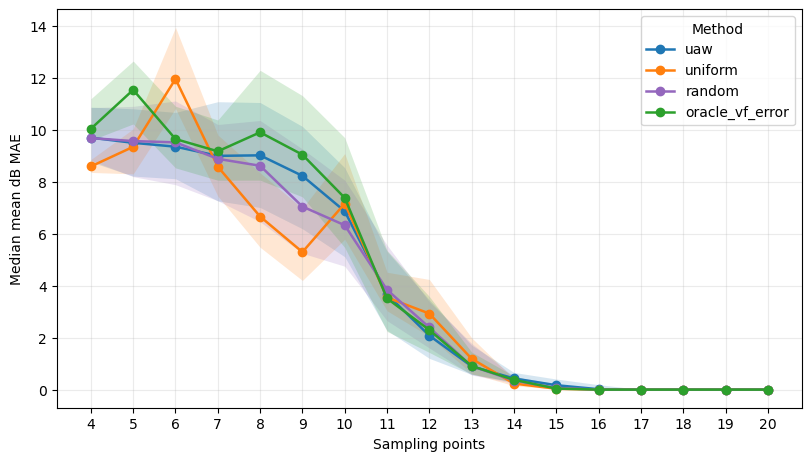

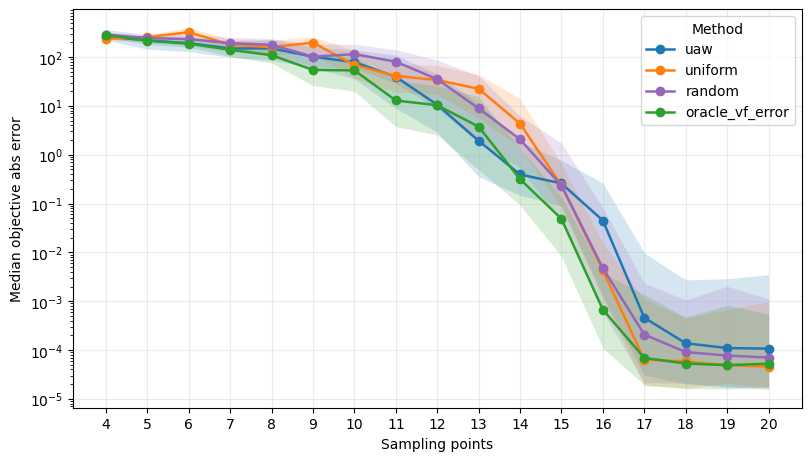

['experiments/uaw_afs_ext_offline_reproduction/plots/sample_count_vs_mean_db_mae.png',
 'experiments/uaw_afs_ext_offline_reproduction/plots/sample_count_vs_objective_abs_error.png']

In [14]:
def parse_semicolon_numbers(value: str, dtype=float) -> np.ndarray:
    if not isinstance(value, str) or not value:
        return np.asarray([], dtype=dtype)
    return np.asarray([dtype(item) for item in value.split(';')], dtype=dtype)


def shade_bands(ax) -> None:
    ax.axvspan(4.8, 5.4, color='#2ca02c', alpha=0.10, label='passband')
    ax.axvspan(3.6, 4.4, color='#d62728', alpha=0.08, label='low stopband')
    ax.axvspan(5.8, 8.7, color='#d62728', alpha=0.08, label='high stopband')


def _plot_metric_vs_sample_count(summary: pd.DataFrame, *, metric: str, ylabel: str, path: Path) -> Path:
    colors = {'uaw': '#1f77b4', 'uniform': '#ff7f0e', 'random': '#9467bd', 'oracle_vf_error': '#2ca02c'}
    fig, ax = plt.subplots(figsize=(8, 4.5), constrained_layout=True)
    q25 = f'q25_{metric}'
    q75 = f'q75_{metric}'
    median = f'median_{metric}'
    positive_values: list[float] = []

    for method in METHODS:
        sub = summary[summary['method'] == method].sort_values('sample_count')
        if sub.empty:
            continue
        x = sub['sample_count'].to_numpy(dtype=float)
        y = sub[median].to_numpy(dtype=float)
        ax.plot(x, y, marker='o', linewidth=1.8, label=method, color=colors[method])
        if q25 in sub.columns and q75 in sub.columns and len(sub) >= 2:
            lo = sub[q25].to_numpy(dtype=float)
            hi = sub[q75].to_numpy(dtype=float)
            ax.fill_between(x, lo, hi, alpha=0.18, color=colors[method], linewidth=0)
        positive_values.extend([float(v) for v in y if np.isfinite(v) and v > 0.0])

    if metric == 'objective_abs_error' and positive_values:
        ratio = max(positive_values) / max(min(positive_values), 1e-12)
        if ratio >= 100.0:
            ax.set_yscale('log')
    ax.set_xlabel('Sampling points')
    ax.set_ylabel(ylabel)
    ax.set_xticks(SAMPLING_NUMS)
    ax.grid(alpha=0.25)
    ax.legend(title='Method')
    fig.savefig(path, dpi=160)
    plt.show()
    plt.close(fig)
    return path


def _plot_representative_reconstructions(payloads: dict[int, dict]) -> list[Path]:
    saved: list[Path] = []
    colors = {'uaw': '#1f77b4', 'uniform': '#ff7f0e', 'random': '#9467bd', 'oracle_vf_error': '#2ca02c'}
    for sample_count in REPRESENTATIVE_COUNTS:
        payload = payloads.get(int(sample_count))
        if payload is None:
            continue
        fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True, constrained_layout=True)
        channels = [('S11', 0, 0), ('S21', 0, 1)]
        for ax, (label, row, col) in zip(axes, channels):
            shade_bands(ax)
            ax.plot(freqs_ghz, channel_db(payload['true_s'], row, col), color='black', linewidth=2, label=f'original {label}')
            for method, pred in payload['preds'].items():
                ax.plot(freqs_ghz, channel_db(pred, row, col), linewidth=1.4, label=f'{method} VF', color=colors[method])
                idx = payload['indices'][method]
                ax.scatter(freqs_ghz[idx], channel_db(payload['true_s'], row, col)[idx], s=14, color=colors[method], alpha=0.75)
            if label == 'S21':
                ax.axhline(-5.0, color='gray', linestyle='--', linewidth=1, label='passband S21 target')
                ax.axhline(-15.0, color='gray', linestyle=':', linewidth=1, label='stopband S21 target')
            else:
                ax.axhline(-7.0, color='gray', linestyle='--', linewidth=1, label='passband S11 target')
            ax.set_ylabel(f'{label} (dB)')
            ax.grid(alpha=0.25)
        axes[-1].set_xlabel('Frequency (GHz)')
        axes[0].set_title(
            f"Representative reconstruction: n={sample_count}, seed={payload['seed']}, sample={payload['sample_idx']}"
        )
        handles, labels = axes[0].get_legend_handles_labels()
        axes[0].legend(handles[:6], labels[:6], loc='best', fontsize=8)
        path = PLOT_DIR / f'representative_s11_s21_reconstruction_n{sample_count:02d}.png'
        fig.savefig(path, dpi=160)
        plt.show()
        plt.close(fig)
        saved.append(path)
    return saved


def write_sweep_plots(summary: pd.DataFrame, payloads: dict[int, dict]) -> list[str]:
    PLOT_DIR.mkdir(parents=True, exist_ok=True)
    saved = [
        _plot_metric_vs_sample_count(
            summary,
            metric='mean_db_mae',
            ylabel='Median mean dB MAE',
            path=PLOT_DIR / 'sample_count_vs_mean_db_mae.png',
        ),
        _plot_metric_vs_sample_count(
            summary,
            metric='objective_abs_error',
            ylabel='Median objective abs error',
            path=PLOT_DIR / 'sample_count_vs_objective_abs_error.png',
        ),
    ]
    saved.extend(_plot_representative_reconstructions(payloads))
    return [relative(path) for path in saved]


plot_paths = write_sweep_plots(sweep_summary_df, representative_payloads)
plot_paths

## Section 5 - Enriched Per-n Analysis

This section turns the sweep table into per-sampling-count diagnostics: which method wins at each `n`, how each method ranks across the sweep, where methods improve over uniform, and how behavior changes between low, middle, and high sampling budgets.

In [15]:
METRIC_SPECS = {
    'mean_db_mae': {
        'median_col': 'median_mean_db_mae',
        'label': 'Median mean dB MAE',
    },
    'objective_abs_error': {
        'median_col': 'median_objective_abs_error',
        'label': 'Median objective abs error',
    },
}


def sampling_regime(sample_count: int) -> str:
    sample_count = int(sample_count)
    if sample_count <= 8:
        return 'low_4_8'
    if sample_count <= 14:
        return 'mid_9_14'
    return 'high_15_20'


def build_best_method_table(summary: pd.DataFrame) -> pd.DataFrame:
    rows: list[dict] = []
    for sample_count, group in summary.groupby('sample_count'):
        record = {'sample_count': int(sample_count), 'regime': sampling_regime(int(sample_count))}
        for metric_name, spec in METRIC_SPECS.items():
            col = spec['median_col']
            best = group.loc[group[col].idxmin()]
            record[f'{metric_name}_best_method'] = str(best['method'])
            record[f'{metric_name}_best_value'] = float(best[col])
            for method in METHODS:
                value = group.loc[group['method'] == method, col]
                record[f'{metric_name}_{method}'] = float(value.iloc[0]) if len(value) else np.nan
        rows.append(record)
    out = pd.DataFrame(rows).sort_values('sample_count')
    out.to_csv(OUTPUT_DIR / 'sample_count_best_methods.csv', index=False)
    return out


def build_rank_tables(summary: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    rank_rows: list[dict] = []
    for metric_name, spec in METRIC_SPECS.items():
        col = spec['median_col']
        for sample_count, group in summary.groupby('sample_count'):
            ranked = group.set_index('method')[col].rank(method='min', ascending=True)
            for method, rank in ranked.items():
                value = group.loc[group['method'] == method, col].iloc[0]
                rank_rows.append({
                    'metric': metric_name,
                    'sample_count': int(sample_count),
                    'regime': sampling_regime(int(sample_count)),
                    'method': str(method),
                    'rank': float(rank),
                    'value': float(value),
                })
    rank_detail = pd.DataFrame(rank_rows).sort_values(['metric', 'sample_count', 'rank', 'method'])
    rank_summary = (
        rank_detail.groupby(['metric', 'method'], as_index=False)
        .agg(
            mean_rank=('rank', 'mean'),
            median_rank=('rank', 'median'),
            best_count=('rank', lambda x: int((x == 1).sum())),
            worst_rank=('rank', 'max'),
        )
        .sort_values(['metric', 'mean_rank', 'method'])
    )
    rank_detail.to_csv(OUTPUT_DIR / 'sample_count_rank_detail.csv', index=False)
    rank_summary.to_csv(OUTPUT_DIR / 'sample_count_rank_summary.csv', index=False)
    return rank_detail, rank_summary


def build_delta_vs_uniform(summary: pd.DataFrame) -> pd.DataFrame:
    rows: list[dict] = []
    for metric_name, spec in METRIC_SPECS.items():
        col = spec['median_col']
        for sample_count, group in summary.groupby('sample_count'):
            uniform_rows = group[group['method'] == 'uniform']
            if uniform_rows.empty:
                continue
            uniform_value = float(uniform_rows[col].iloc[0])
            for _, row in group.iterrows():
                method_value = float(row[col])
                rows.append({
                    'metric': metric_name,
                    'sample_count': int(sample_count),
                    'regime': sampling_regime(int(sample_count)),
                    'method': str(row['method']),
                    'method_value': method_value,
                    'uniform_value': uniform_value,
                    'delta_vs_uniform': method_value - uniform_value,
                    'ratio_vs_uniform': method_value / uniform_value if uniform_value > 0 else np.nan,
                    'beats_uniform': bool(method_value < uniform_value),
                })
    out = pd.DataFrame(rows).sort_values(['metric', 'sample_count', 'method'])
    out.to_csv(OUTPUT_DIR / 'sample_count_delta_vs_uniform.csv', index=False)
    return out


def build_regime_summary(summary: pd.DataFrame, rank_detail: pd.DataFrame) -> pd.DataFrame:
    metric_frames = []
    for metric_name, spec in METRIC_SPECS.items():
        col = spec['median_col']
        tmp = summary.copy()
        tmp['metric'] = metric_name
        tmp['regime'] = tmp['sample_count'].map(sampling_regime)
        grouped = (
            tmp.groupby(['metric', 'regime', 'method'], as_index=False)
            .agg(
                regime_median_value=(col, 'median'),
                regime_mean_value=(col, 'mean'),
                best_count=(col, lambda x: 0),
            )
        )
        metric_frames.append(grouped)
    out = pd.concat(metric_frames, ignore_index=True)
    best_counts = (
        rank_detail[rank_detail['rank'] == 1]
        .groupby(['metric', 'regime', 'method'], as_index=False)
        .size()
        .rename(columns={'size': 'best_count'})
    )
    out = out.drop(columns=['best_count']).merge(
        best_counts,
        on=['metric', 'regime', 'method'],
        how='left',
    )
    mean_ranks = (
        rank_detail.groupby(['metric', 'regime', 'method'], as_index=False)
        .agg(regime_mean_rank=('rank', 'mean'))
    )
    out = out.merge(mean_ranks, on=['metric', 'regime', 'method'], how='left')
    out['best_count'] = out['best_count'].fillna(0).astype(int)
    out = out.sort_values(['metric', 'regime', 'regime_mean_rank', 'method'])
    out.to_csv(OUTPUT_DIR / 'sample_count_regime_summary.csv', index=False)
    return out


best_method_df = build_best_method_table(sweep_summary_df)
rank_detail_df, rank_summary_df = build_rank_tables(sweep_summary_df)
delta_vs_uniform_df = build_delta_vs_uniform(sweep_summary_df)
regime_summary_df = build_regime_summary(sweep_summary_df, rank_detail_df)

best_method_df.head(), rank_summary_df, regime_summary_df.head(12)

(   sample_count   regime mean_db_mae_best_method  mean_db_mae_best_value  \
 0             4  low_4_8                 uniform                8.598661   
 1             5  low_4_8                 uniform                9.355249   
 2             6  low_4_8                     uaw                9.360368   
 3             7  low_4_8                 uniform                8.590154   
 4             8  low_4_8                 uniform                6.669357   
 
    mean_db_mae_uaw  mean_db_mae_uniform  mean_db_mae_random  \
 0         9.706458             8.598661            9.691621   
 1         9.509699             9.355249            9.576100   
 2         9.360368            11.970335            9.526552   
 3         9.006666             8.590154            8.891643   
 4         9.026380             6.669357            8.625281   
 
    mean_db_mae_oracle_vf_error objective_abs_error_best_method  \
 0                    10.049311                         uniform   
 1              

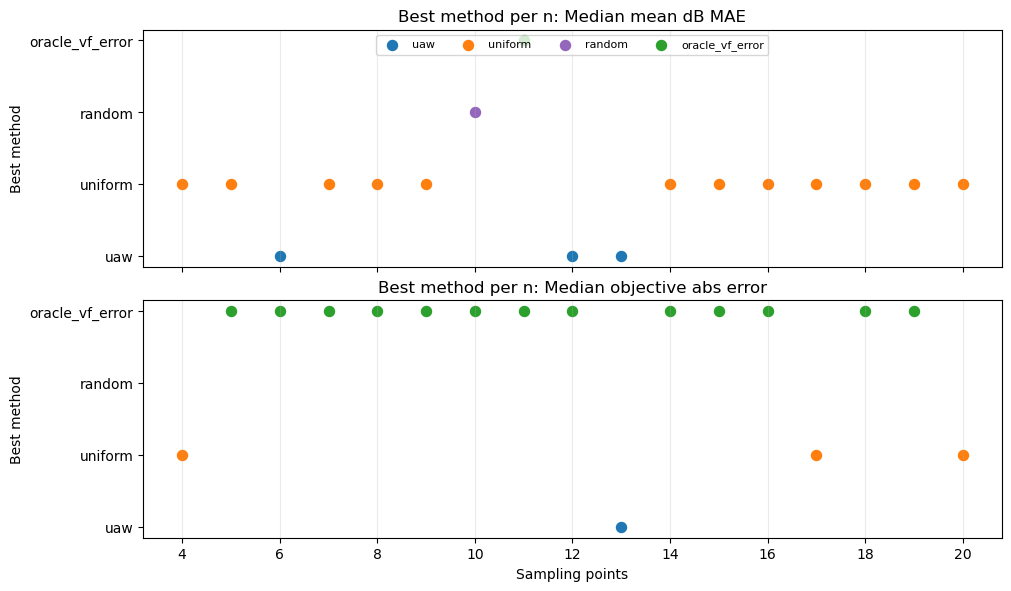

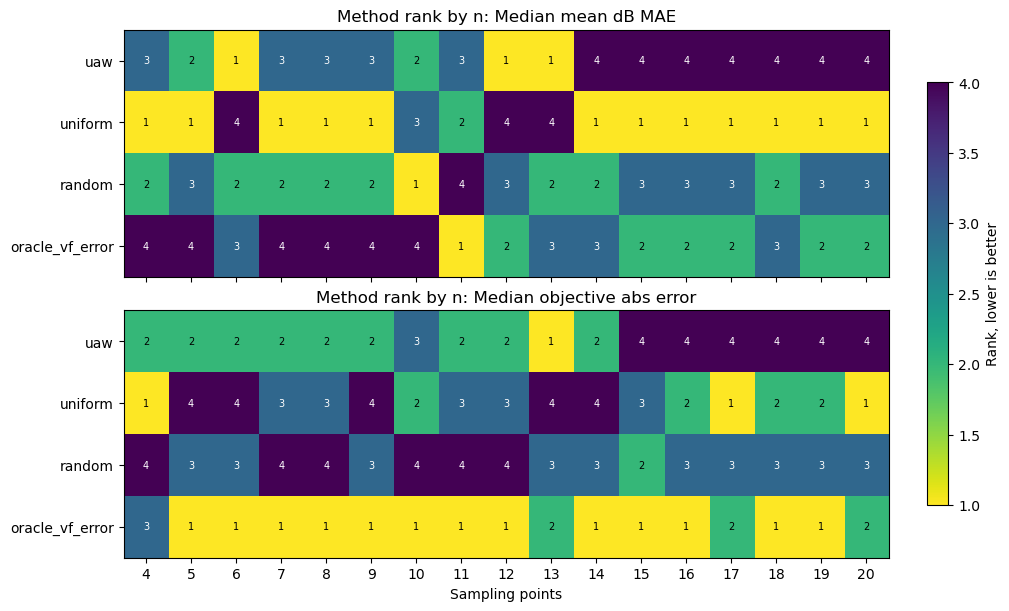

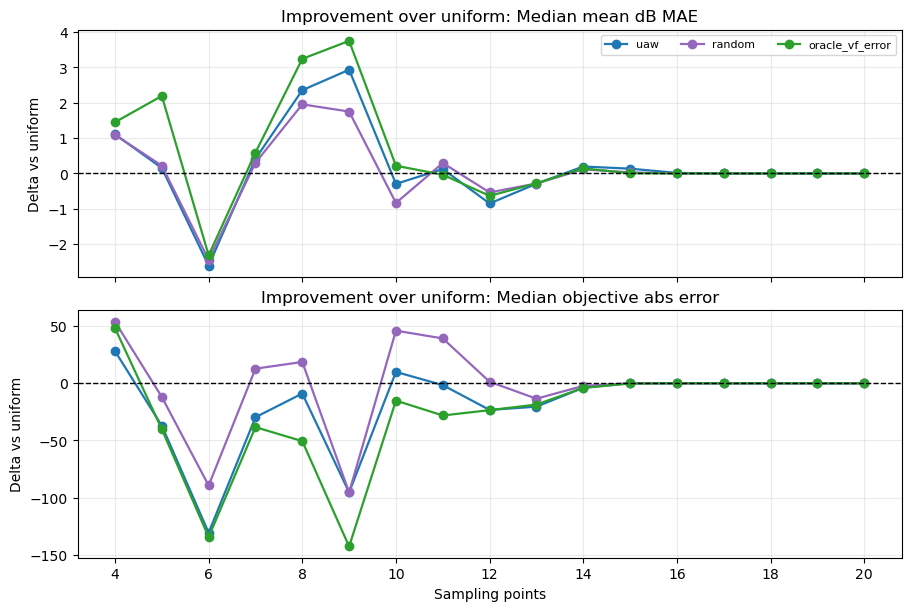

['experiments/uaw_afs_ext_offline_reproduction/plots/sample_count_best_method_by_metric.png',
 'experiments/uaw_afs_ext_offline_reproduction/plots/sample_count_rank_heatmap.png',
 'experiments/uaw_afs_ext_offline_reproduction/plots/sample_count_delta_vs_uniform.png']

In [16]:
def write_enriched_analysis_plots(
    best_methods: pd.DataFrame,
    rank_detail: pd.DataFrame,
    delta_vs_uniform: pd.DataFrame,
) -> list[str]:
    PLOT_DIR.mkdir(parents=True, exist_ok=True)
    saved: list[Path] = []
    colors = {'uaw': '#1f77b4', 'uniform': '#ff7f0e', 'random': '#9467bd', 'oracle_vf_error': '#2ca02c'}

    fig, axes = plt.subplots(2, 1, figsize=(10, 5.8), sharex=True, constrained_layout=True)
    for ax, metric_name in zip(axes, METRIC_SPECS):
        method_col = f'{metric_name}_best_method'
        for method in METHODS:
            sub = best_methods[best_methods[method_col] == method]
            if sub.empty:
                continue
            ax.scatter(sub['sample_count'], np.full(len(sub), METHODS.index(method)), s=52, color=colors[method], label=method)
        ax.set_yticks(range(len(METHODS)), METHODS)
        ax.set_ylabel('Best method')
        ax.set_title(f"Best method per n: {METRIC_SPECS[metric_name]['label']}")
        ax.grid(axis='x', alpha=0.25)
    axes[-1].set_xlabel('Sampling points')
    handles, labels = axes[0].get_legend_handles_labels()
    axes[0].legend(handles, labels, ncol=4, fontsize=8, loc='upper center')
    path = PLOT_DIR / 'sample_count_best_method_by_metric.png'
    fig.savefig(path, dpi=160)
    plt.show()
    plt.close(fig)
    saved.append(path)

    fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True, constrained_layout=True)
    for ax, metric_name in zip(axes, METRIC_SPECS):
        pivot = (
            rank_detail[rank_detail['metric'] == metric_name]
            .pivot(index='method', columns='sample_count', values='rank')
            .reindex(METHODS)
        )
        im = ax.imshow(pivot.to_numpy(dtype=float), aspect='auto', vmin=1, vmax=len(METHODS), cmap='viridis_r')
        ax.set_yticks(np.arange(len(METHODS)), METHODS)
        ax.set_title(f"Method rank by n: {METRIC_SPECS[metric_name]['label']}")
        ax.set_xticks(np.arange(len(SAMPLING_NUMS)), SAMPLING_NUMS)
        for y, method in enumerate(METHODS):
            for x, sample_count in enumerate(SAMPLING_NUMS):
                value = pivot.loc[method, sample_count]
                ax.text(x, y, f'{int(value)}', ha='center', va='center', fontsize=7, color='white' if value >= 3 else 'black')
    axes[-1].set_xlabel('Sampling points')
    fig.colorbar(im, ax=axes, shrink=0.8, label='Rank, lower is better')
    path = PLOT_DIR / 'sample_count_rank_heatmap.png'
    fig.savefig(path, dpi=160)
    plt.show()
    plt.close(fig)
    saved.append(path)

    fig, axes = plt.subplots(2, 1, figsize=(9, 6), sharex=True, constrained_layout=True)
    for ax, metric_name in zip(axes, METRIC_SPECS):
        sub = delta_vs_uniform[(delta_vs_uniform['metric'] == metric_name) & (delta_vs_uniform['method'] != 'uniform')]
        for method in [m for m in METHODS if m != 'uniform']:
            method_rows = sub[sub['method'] == method].sort_values('sample_count')
            ax.plot(
                method_rows['sample_count'],
                method_rows['delta_vs_uniform'],
                marker='o',
                linewidth=1.6,
                color=colors[method],
                label=method,
            )
        ax.axhline(0.0, color='black', linewidth=1, linestyle='--')
        ax.set_ylabel('Delta vs uniform')
        ax.set_title(f"Improvement over uniform: {METRIC_SPECS[metric_name]['label']}")
        ax.grid(alpha=0.25)
    axes[-1].set_xlabel('Sampling points')
    axes[0].legend(ncol=3, fontsize=8)
    path = PLOT_DIR / 'sample_count_delta_vs_uniform.png'
    fig.savefig(path, dpi=160)
    plt.show()
    plt.close(fig)
    saved.append(path)

    return [relative(path) for path in saved]


enriched_plot_paths = write_enriched_analysis_plots(best_method_df, rank_detail_df, delta_vs_uniform_df)
plot_paths = list(dict.fromkeys([*plot_paths, *enriched_plot_paths]))
enriched_plot_paths

## Section 6 - VF Order-Matched Rerun

This rerun keeps the same sampled-frequency methods and smoke split, but changes the VF order policy. For each target sample count `n`, VF uses `floor(n / 2)` actual poles and the same number of residue terms, so pole-plus-residue terms never exceed the sampled frequency budget. The original fixed-order sweep remains available as the baseline artifacts above.

In [17]:

ORDER_MATCHED_VF_POLICY = VF_ORDER_POLICY_ORDER_MATCHED
ORDER_MATCHED_METHODS = ['uniform', 'random', 'uaw', 'oracle_vf_error']
ORDER_MATCHED_SUFFIX = '_order_matched'


def add_order_metadata(row: dict, indices: np.ndarray, policy: str) -> dict:
    out = dict(row)
    out.update(vf_order_for_sample_count(len(indices), policy))
    return out


def run_order_matched_sampling_count_sweep(config: dict, states: dict[int, dict]) -> tuple[pd.DataFrame, dict[int, dict]]:
    rows: list[dict] = []
    representative_payloads: dict[int, dict] = {}

    for seed in config['seeds']:
        state = states[int(seed)]
        surrogate = state['surrogate']
        eval_idx = state['eval_idx']
        _, response_samples = surrogate.predict_s_params(
            dataset,
            eval_idx,
            mc_samples=int(config['mc_samples']),
            return_samples=True,
        )

        for local_pos, sample_idx in enumerate(eval_idx):
            sample_idx = int(sample_idx)
            true_s = dataset.s_params[sample_idx]
            profile = uncertainty_profile_from_samples(response_samples, local_pos)
            true_obj = objective_value(true_s)
            oracle_index_cache = (
                select_oracle_vf_error_index_path(
                    true_s,
                    SAMPLING_NUMS,
                    vf_order_policy=ORDER_MATCHED_VF_POLICY,
                )
                if 'oracle_vf_error' in ORDER_MATCHED_METHODS
                else {}
            )

            for sample_count in SAMPLING_NUMS:
                example_preds: dict[str, np.ndarray] = {}
                example_indices: dict[str, np.ndarray] = {}

                for method in ORDER_MATCHED_METHODS:
                    if method == 'oracle_vf_error':
                        indices = oracle_index_cache[int(sample_count)]
                    else:
                        indices = select_frequency_indices(
                            method,
                            profile,
                            int(sample_count),
                            sweep_method_rng(int(seed), sample_idx, method, int(sample_count)),
                        )

                    fit_t0 = time.perf_counter()
                    try:
                        pred_s = reconstruct_sparams(true_s, indices, vf_order_policy=ORDER_MATCHED_VF_POLICY)
                        fit_sec = float(time.perf_counter() - fit_t0)
                        row = successful_reconstruction_row(
                            state=state,
                            sample_idx=sample_idx,
                            sample_count=int(sample_count),
                            method=method,
                            indices=indices,
                            true_s=true_s,
                            pred_s=pred_s,
                            true_obj=true_obj,
                            fit_sec=fit_sec,
                        )
                        rows.append(add_order_metadata(row, indices, ORDER_MATCHED_VF_POLICY))
                        if sample_count in REPRESENTATIVE_COUNTS and sample_count not in representative_payloads:
                            example_preds[method] = pred_s
                            example_indices[method] = indices
                    except Exception as exc:
                        fit_sec = float(time.perf_counter() - fit_t0)
                        row = empty_reconstruction_row(
                            state=state,
                            sample_idx=sample_idx,
                            sample_count=int(sample_count),
                            method=method,
                            indices=indices,
                            true_obj=true_obj,
                            fit_sec=fit_sec,
                            error=exc,
                        )
                        rows.append(add_order_metadata(row, indices, ORDER_MATCHED_VF_POLICY))

                if sample_count in REPRESENTATIVE_COUNTS and sample_count not in representative_payloads and len(example_preds) == len(ORDER_MATCHED_METHODS):
                    representative_payloads[int(sample_count)] = {
                        'seed': int(seed),
                        'sample_idx': sample_idx,
                        'sample_count': int(sample_count),
                        'case_id': dataset.case_ids[sample_idx],
                        'true_s': true_s.copy(),
                        'preds': example_preds,
                        'indices': example_indices,
                        'uncertainty_profile': profile.copy(),
                    }

    out = pd.DataFrame(rows)
    out.to_csv(OUTPUT_DIR / 'sample_count_sweep_rows_order_matched.csv', index=False)
    out[out['sample_count'] == max(SAMPLING_NUMS)].copy().to_csv(
        OUTPUT_DIR / 'reconstruction_rows_order_matched.csv',
        index=False,
    )
    return out, representative_payloads


order_matched_rows_df, order_matched_representative_payloads = run_order_matched_sampling_count_sweep(CONFIG, model_states)
order_matched_rows_df.head()


,seed,sample_idx,case_id,filename,sample_count,method,status,error,model_status,model_path,...,s21_db_max_error,mean_db_mae,objective_abs_error,true_objective,pred_objective,vf_order_policy,vf_actual_poles,vf_n_poles_real,vf_n_poles_complex,vf_pole_residue_terms
0,0,98,bo_online_general_seed0_it0019,Bandpass_Coupled_Line_Filter_export_Bandpass_C...,4,uniform,ok,None,loaded,experiments/uaw_afs_ext_offline_reproduction/m...,...,42.936152,9.720205,239.783171,25.241529,265.024700,pole_residue_budget,2,0,1,4
1,0,98,bo_online_general_seed0_it0019,Bandpass_Coupled_Line_Filter_export_Bandpass_C...,4,random,ok,None,loaded,experiments/uaw_afs_ext_offline_reproduction/m...,...,29.090500,5.761898,117.553187,25.241529,142.794716,pole_residue_budget,2,0,1,4
2,0,98,bo_online_general_seed0_it0019,Bandpass_Coupled_Line_Filter_export_Bandpass_C...,4,uaw,ok,None,loaded,experiments/uaw_afs_ext_offline_reproduction/m...,...,32.520459,6.488788,104.802829,25.241529,130.044358,pole_residue_budget,2,0,1,4
3,0,98,bo_online_general_seed0_it0019,Bandpass_Coupled_Line_Filter_export_Bandpass_C...,4,oracle_vf_error,ok,None,loaded,experiments/uaw_afs_ext_offline_reproduction/m...,...,39.508749,7.025516,186.333008,25.241529,211.574537,pole_residue_budget,2,0,1,4
4,0,98,bo_online_general_seed0_it0019,Bandpass_Coupled_Line_Filter_export_Bandpass_C...,5,uniform,ok,None,loaded,experiments/uaw_afs_ext_offline_reproduction/m...,...,42.492031,8.665025,237.834424,25.241529,263.075953,pole_residue_budget,2,0,1,4


In [18]:

def csv_path_with_suffix(stem: str, suffix: str) -> Path:
    return OUTPUT_DIR / f'{stem}{suffix}.csv'


def summarize_sweep_to_files(rows: pd.DataFrame, suffix: str) -> tuple[pd.DataFrame, pd.DataFrame]:
    ok = rows[rows['status'] == 'ok'].copy()
    metric_aggs = dict(
        cases=('sample_idx', 'count'),
        median_mean_db_mae=('mean_db_mae', 'median'),
        mean_mean_db_mae=('mean_db_mae', 'mean'),
        q25_mean_db_mae=('mean_db_mae', lambda x: float(np.quantile(x, 0.25))),
        q75_mean_db_mae=('mean_db_mae', lambda x: float(np.quantile(x, 0.75))),
        median_objective_abs_error=('objective_abs_error', 'median'),
        mean_objective_abs_error=('objective_abs_error', 'mean'),
        q25_objective_abs_error=('objective_abs_error', lambda x: float(np.quantile(x, 0.25))),
        q75_objective_abs_error=('objective_abs_error', lambda x: float(np.quantile(x, 0.75))),
        median_s11_db_mae=('s11_db_mae', 'median'),
        median_s21_db_mae=('s21_db_mae', 'median'),
        median_vf_fit_sec=('vf_fit_sec', 'median'),
        vf_actual_poles=('vf_actual_poles', 'first'),
        vf_n_poles_real=('vf_n_poles_real', 'first'),
        vf_n_poles_complex=('vf_n_poles_complex', 'first'),
        vf_pole_residue_terms=('vf_pole_residue_terms', 'first'),
    )
    summary = (
        ok.groupby(['sample_count', 'method'], as_index=False)
        .agg(**metric_aggs)
        .sort_values(['sample_count', 'method'])
    )
    summary['vf_order_policy'] = ORDER_MATCHED_VF_POLICY
    summary.to_csv(csv_path_with_suffix('sample_count_sweep_summary', suffix), index=False)

    pairs = []
    for metric in ['mean_db_mae', 'objective_abs_error']:
        wide = ok.pivot_table(
            index=['seed', 'sample_idx', 'sample_count'],
            columns='method',
            values=metric,
            aggfunc='first',
        ).dropna()
        for sample_count in SAMPLING_NUMS:
            by_count = wide[wide.index.get_level_values('sample_count') == sample_count]
            for left, right in [('uaw', 'uniform'), ('uaw', 'random'), ('oracle_vf_error', 'uniform'), ('oracle_vf_error', 'random'), ('oracle_vf_error', 'uaw')]:
                if {left, right}.issubset(by_count.columns):
                    delta = by_count[left] - by_count[right]
                    pairs.append({
                        'sample_count': int(sample_count),
                        'metric': metric,
                        'comparison': f'{left}_vs_{right}',
                        'paired_cases': int(len(by_count)),
                        'left_win_rate': float((by_count[left] <= by_count[right]).mean()) if len(by_count) else np.nan,
                        'left_median_delta': float(delta.median()) if len(by_count) else np.nan,
                        'left_mean_delta': float(delta.mean()) if len(by_count) else np.nan,
                        'vf_order_policy': ORDER_MATCHED_VF_POLICY,
                    })
    paired = pd.DataFrame(pairs)
    paired.to_csv(csv_path_with_suffix('sample_count_sweep_paired', suffix), index=False)
    return summary, paired


def summarize_max_count_to_files(rows: pd.DataFrame, suffix: str) -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    ok = rows[rows['status'] == 'ok'].copy()
    metric_aggs = dict(
        cases=('sample_idx', 'count'),
        median_mean_db_mae=('mean_db_mae', 'median'),
        mean_mean_db_mae=('mean_db_mae', 'mean'),
        median_s11_db_mae=('s11_db_mae', 'median'),
        median_s21_db_mae=('s21_db_mae', 'median'),
        median_objective_abs_error=('objective_abs_error', 'median'),
        mean_objective_abs_error=('objective_abs_error', 'mean'),
        median_vf_fit_sec=('vf_fit_sec', 'median'),
        vf_actual_poles=('vf_actual_poles', 'first'),
        vf_n_poles_real=('vf_n_poles_real', 'first'),
        vf_n_poles_complex=('vf_n_poles_complex', 'first'),
        vf_pole_residue_terms=('vf_pole_residue_terms', 'first'),
    )
    summary_by_seed_method = (
        ok.groupby(['seed', 'method'], as_index=False)
        .agg(**metric_aggs)
        .sort_values(['seed', 'method'])
    )
    summary_overall = (
        ok.groupby(['method'], as_index=False)
        .agg(**metric_aggs)
        .sort_values('method')
    )
    pairs = []
    for metric in ['mean_db_mae', 'objective_abs_error']:
        wide = ok.pivot_table(index=['seed', 'sample_idx'], columns='method', values=metric, aggfunc='first').dropna()
        for left, right in [('uaw', 'uniform'), ('uaw', 'random'), ('oracle_vf_error', 'uniform'), ('oracle_vf_error', 'random'), ('oracle_vf_error', 'uaw')]:
            if {left, right}.issubset(wide.columns):
                delta = wide[left] - wide[right]
                pairs.append({
                    'metric': metric,
                    'comparison': f'{left}_vs_{right}',
                    'paired_cases': int(len(wide)),
                    'left_win_rate': float((wide[left] <= wide[right]).mean()) if len(wide) else np.nan,
                    'left_median_delta': float(delta.median()) if len(wide) else np.nan,
                    'left_mean_delta': float(delta.mean()) if len(wide) else np.nan,
                    'vf_order_policy': ORDER_MATCHED_VF_POLICY,
                })
    paired = pd.DataFrame(pairs)
    summary_by_seed_method['vf_order_policy'] = ORDER_MATCHED_VF_POLICY
    summary_overall['vf_order_policy'] = ORDER_MATCHED_VF_POLICY
    summary_by_seed_method.to_csv(csv_path_with_suffix('summary_by_seed_method', suffix), index=False)
    summary_overall.to_csv(csv_path_with_suffix('summary_overall', suffix), index=False)
    paired.to_csv(csv_path_with_suffix('paired_uaw_vs_baselines', suffix), index=False)
    return summary_by_seed_method, summary_overall, paired


order_matched_summary_df, order_matched_paired_df = summarize_sweep_to_files(order_matched_rows_df, ORDER_MATCHED_SUFFIX)
order_matched_rows_max_df = order_matched_rows_df[order_matched_rows_df['sample_count'] == max(SAMPLING_NUMS)].copy()
order_matched_summary_by_seed_method_df, order_matched_summary_overall_df, order_matched_max_paired_df = summarize_max_count_to_files(
    order_matched_rows_max_df,
    ORDER_MATCHED_SUFFIX,
)
order_matched_summary_df.head()


,sample_count,method,cases,median_mean_db_mae,mean_mean_db_mae,q25_mean_db_mae,q75_mean_db_mae,median_objective_abs_error,mean_objective_abs_error,q25_objective_abs_error,q75_objective_abs_error,median_s11_db_mae,median_s21_db_mae,median_vf_fit_sec,vf_actual_poles,vf_n_poles_real,vf_n_poles_complex,vf_pole_residue_terms,vf_order_policy
0,4,oracle_vf_error,250,6.715583,6.736461,6.406729,7.024132,192.597255,189.219182,170.899651,207.696974,1.306341,12.102911,0.008506,2,0,1,4,pole_residue_budget
1,4,random,250,8.035952,8.208711,6.555675,9.942856,208.956346,196.680945,142.712136,260.432175,2.891530,13.430330,0.008582,2,0,1,4,pole_residue_budget
2,4,uaw,250,6.750464,7.128664,5.705969,8.262051,140.937002,143.054073,83.249889,187.530763,2.685073,10.504193,0.008565,2,0,1,4,pole_residue_budget
3,4,uniform,250,10.200003,9.969690,9.485070,10.665515,256.057238,251.639751,233.748174,276.813233,2.902240,17.531639,0.008509,2,0,1,4,pole_residue_budget
4,5,oracle_vf_error,250,5.416677,5.502604,5.160976,5.699361,110.342736,108.085083,96.637154,122.384779,2.000759,8.681539,0.008512,2,0,1,4,pole_residue_budget


In [19]:

def build_best_method_table_to_file(summary: pd.DataFrame, suffix: str) -> pd.DataFrame:
    rows: list[dict] = []
    for sample_count, group in summary.groupby('sample_count'):
        record = {'sample_count': int(sample_count), 'regime': sampling_regime(int(sample_count))}
        for metric_name, spec in METRIC_SPECS.items():
            col = spec['median_col']
            best = group.loc[group[col].idxmin()]
            record[f'{metric_name}_best_method'] = str(best['method'])
            record[f'{metric_name}_best_value'] = float(best[col])
            for method in METHODS:
                value = group.loc[group['method'] == method, col]
                record[f'{metric_name}_{method}'] = float(value.iloc[0]) if len(value) else np.nan
        rows.append(record)
    out = pd.DataFrame(rows).sort_values('sample_count')
    out.to_csv(csv_path_with_suffix('sample_count_best_methods', suffix), index=False)
    return out


def build_rank_tables_to_file(summary: pd.DataFrame, suffix: str) -> tuple[pd.DataFrame, pd.DataFrame]:
    rank_rows: list[dict] = []
    for metric_name, spec in METRIC_SPECS.items():
        col = spec['median_col']
        for sample_count, group in summary.groupby('sample_count'):
            ranked = group.set_index('method')[col].rank(method='min', ascending=True)
            for method, rank in ranked.items():
                value = group.loc[group['method'] == method, col].iloc[0]
                rank_rows.append({
                    'metric': metric_name,
                    'sample_count': int(sample_count),
                    'regime': sampling_regime(int(sample_count)),
                    'method': str(method),
                    'rank': float(rank),
                    'value': float(value),
                    'vf_order_policy': ORDER_MATCHED_VF_POLICY,
                })
    rank_detail = pd.DataFrame(rank_rows).sort_values(['metric', 'sample_count', 'rank', 'method'])
    rank_summary = (
        rank_detail.groupby(['metric', 'method'], as_index=False)
        .agg(
            mean_rank=('rank', 'mean'),
            median_rank=('rank', 'median'),
            best_count=('rank', lambda x: int((x == 1).sum())),
            worst_rank=('rank', 'max'),
        )
        .sort_values(['metric', 'mean_rank', 'method'])
    )
    rank_summary['vf_order_policy'] = ORDER_MATCHED_VF_POLICY
    rank_detail.to_csv(csv_path_with_suffix('sample_count_rank_detail', suffix), index=False)
    rank_summary.to_csv(csv_path_with_suffix('sample_count_rank_summary', suffix), index=False)
    return rank_detail, rank_summary


def build_delta_vs_uniform_to_file(summary: pd.DataFrame, suffix: str) -> pd.DataFrame:
    rows: list[dict] = []
    for metric_name, spec in METRIC_SPECS.items():
        col = spec['median_col']
        for sample_count, group in summary.groupby('sample_count'):
            uniform_rows = group[group['method'] == 'uniform']
            if uniform_rows.empty:
                continue
            uniform_value = float(uniform_rows[col].iloc[0])
            for _, row in group.iterrows():
                method_value = float(row[col])
                rows.append({
                    'metric': metric_name,
                    'sample_count': int(sample_count),
                    'regime': sampling_regime(int(sample_count)),
                    'method': str(row['method']),
                    'method_value': method_value,
                    'uniform_value': uniform_value,
                    'delta_vs_uniform': method_value - uniform_value,
                    'ratio_vs_uniform': method_value / uniform_value if uniform_value > 0 else np.nan,
                    'beats_uniform': bool(method_value < uniform_value),
                    'vf_order_policy': ORDER_MATCHED_VF_POLICY,
                })
    out = pd.DataFrame(rows).sort_values(['metric', 'sample_count', 'method'])
    out.to_csv(csv_path_with_suffix('sample_count_delta_vs_uniform', suffix), index=False)
    return out


def build_regime_summary_to_file(summary: pd.DataFrame, rank_detail: pd.DataFrame, suffix: str) -> pd.DataFrame:
    metric_frames = []
    for metric_name, spec in METRIC_SPECS.items():
        col = spec['median_col']
        tmp = summary.copy()
        tmp['metric'] = metric_name
        tmp['regime'] = tmp['sample_count'].map(sampling_regime)
        grouped = (
            tmp.groupby(['metric', 'regime', 'method'], as_index=False)
            .agg(
                regime_median_value=(col, 'median'),
                regime_mean_value=(col, 'mean'),
                best_count=(col, lambda x: 0),
            )
        )
        metric_frames.append(grouped)
    out = pd.concat(metric_frames, ignore_index=True)
    best_counts = (
        rank_detail[rank_detail['rank'] == 1]
        .groupby(['metric', 'regime', 'method'], as_index=False)
        .size()
        .rename(columns={'size': 'best_count'})
    )
    out = out.drop(columns=['best_count']).merge(
        best_counts,
        on=['metric', 'regime', 'method'],
        how='left',
    )
    mean_ranks = (
        rank_detail.groupby(['metric', 'regime', 'method'], as_index=False)
        .agg(regime_mean_rank=('rank', 'mean'))
    )
    out = out.merge(mean_ranks, on=['metric', 'regime', 'method'], how='left')
    out['best_count'] = out['best_count'].fillna(0).astype(int)
    out['vf_order_policy'] = ORDER_MATCHED_VF_POLICY
    out = out.sort_values(['metric', 'regime', 'regime_mean_rank', 'method'])
    out.to_csv(csv_path_with_suffix('sample_count_regime_summary', suffix), index=False)
    return out


order_matched_best_method_df = build_best_method_table_to_file(order_matched_summary_df, ORDER_MATCHED_SUFFIX)
order_matched_rank_detail_df, order_matched_rank_summary_df = build_rank_tables_to_file(order_matched_summary_df, ORDER_MATCHED_SUFFIX)
order_matched_delta_vs_uniform_df = build_delta_vs_uniform_to_file(order_matched_summary_df, ORDER_MATCHED_SUFFIX)
order_matched_regime_summary_df = build_regime_summary_to_file(
    order_matched_summary_df,
    order_matched_rank_detail_df,
    ORDER_MATCHED_SUFFIX,
)
order_matched_best_method_df.head(), order_matched_rank_summary_df


(   sample_count   regime mean_db_mae_best_method  mean_db_mae_best_value  \
 0             4  low_4_8         oracle_vf_error                6.715583   
 1             5  low_4_8         oracle_vf_error                5.416677   
 2             6  low_4_8                 uniform                5.772003   
 3             7  low_4_8                 uniform                4.971724   
 4             8  low_4_8                 uniform                3.368047   
 
    mean_db_mae_uaw  mean_db_mae_uniform  mean_db_mae_random  \
 0         6.750464            10.200003            8.035952   
 1         6.983219             7.654499            7.511175   
 2         6.786222             5.772003            5.966178   
 3         7.530321             4.971724            6.156871   
 4         4.668421             3.368047            4.116333   
 
    mean_db_mae_oracle_vf_error objective_abs_error_best_method  \
 0                     6.715583                             uaw   
 1              

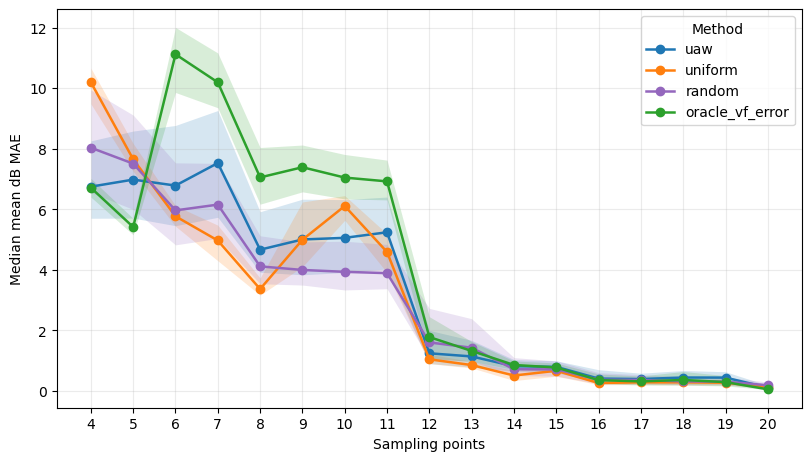

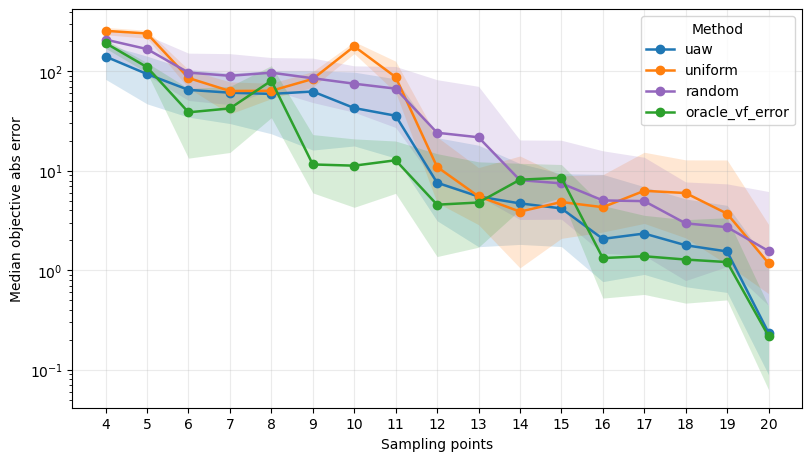

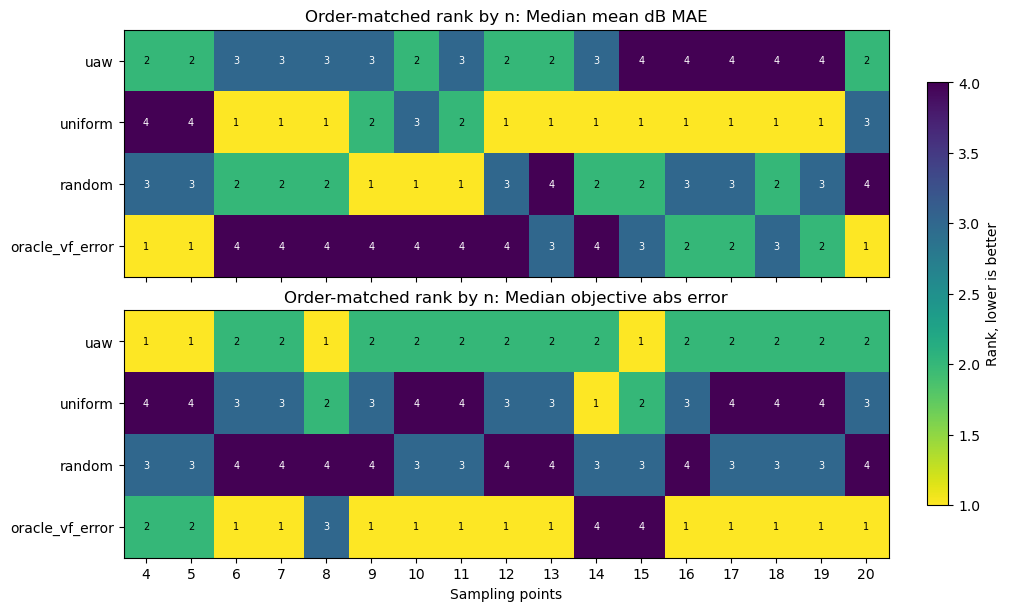

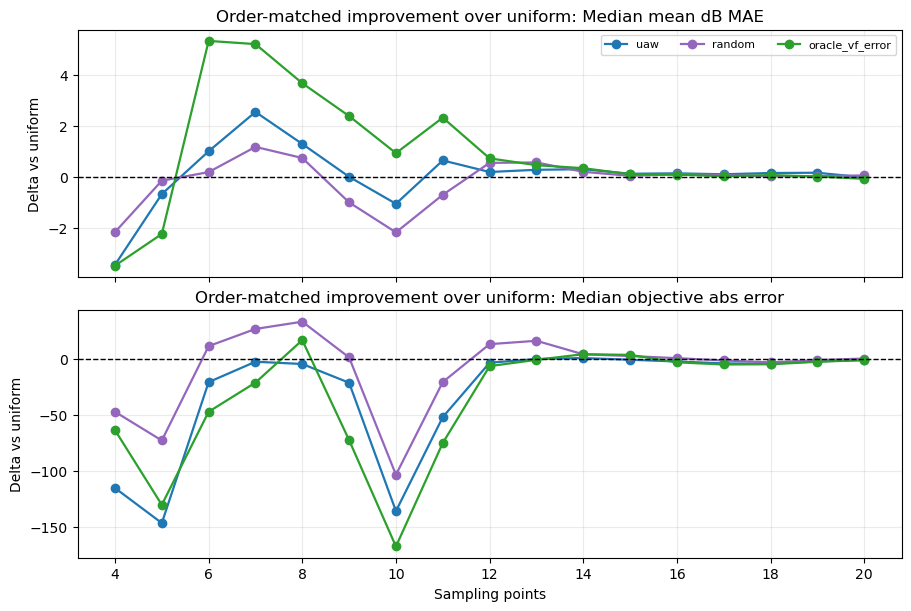

['experiments/uaw_afs_ext_offline_reproduction/plots/order_matched_sample_count_vs_mean_db_mae.png',
 'experiments/uaw_afs_ext_offline_reproduction/plots/order_matched_sample_count_vs_objective_abs_error.png',
 'experiments/uaw_afs_ext_offline_reproduction/plots/order_matched_sample_count_rank_heatmap.png',
 'experiments/uaw_afs_ext_offline_reproduction/plots/order_matched_delta_vs_uniform.png']

In [20]:

def write_order_matched_analysis_plots(
    summary: pd.DataFrame,
    rank_detail: pd.DataFrame,
    delta_vs_uniform: pd.DataFrame,
) -> list[str]:
    PLOT_DIR.mkdir(parents=True, exist_ok=True)
    saved: list[Path] = []
    colors = {'uaw': '#1f77b4', 'uniform': '#ff7f0e', 'random': '#9467bd', 'oracle_vf_error': '#2ca02c'}

    saved.append(
        _plot_metric_vs_sample_count(
            summary,
            metric='mean_db_mae',
            ylabel='Median mean dB MAE',
            path=PLOT_DIR / 'order_matched_sample_count_vs_mean_db_mae.png',
        )
    )
    saved.append(
        _plot_metric_vs_sample_count(
            summary,
            metric='objective_abs_error',
            ylabel='Median objective abs error',
            path=PLOT_DIR / 'order_matched_sample_count_vs_objective_abs_error.png',
        )
    )

    fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True, constrained_layout=True)
    for ax, metric_name in zip(axes, METRIC_SPECS):
        pivot = (
            rank_detail[rank_detail['metric'] == metric_name]
            .pivot(index='method', columns='sample_count', values='rank')
            .reindex(METHODS)
        )
        im = ax.imshow(pivot.to_numpy(dtype=float), aspect='auto', vmin=1, vmax=len(METHODS), cmap='viridis_r')
        ax.set_yticks(np.arange(len(METHODS)), METHODS)
        ax.set_title(f"Order-matched rank by n: {METRIC_SPECS[metric_name]['label']}")
        ax.set_xticks(np.arange(len(SAMPLING_NUMS)), SAMPLING_NUMS)
        for y, method in enumerate(METHODS):
            for x, sample_count in enumerate(SAMPLING_NUMS):
                value = pivot.loc[method, sample_count]
                ax.text(x, y, f'{int(value)}', ha='center', va='center', fontsize=7, color='white' if value >= 3 else 'black')
    axes[-1].set_xlabel('Sampling points')
    fig.colorbar(im, ax=axes, shrink=0.8, label='Rank, lower is better')
    path = PLOT_DIR / 'order_matched_sample_count_rank_heatmap.png'
    fig.savefig(path, dpi=160)
    plt.show()
    plt.close(fig)
    saved.append(path)

    fig, axes = plt.subplots(2, 1, figsize=(9, 6), sharex=True, constrained_layout=True)
    for ax, metric_name in zip(axes, METRIC_SPECS):
        sub = delta_vs_uniform[(delta_vs_uniform['metric'] == metric_name) & (delta_vs_uniform['method'] != 'uniform')]
        for method in [m for m in METHODS if m != 'uniform']:
            method_rows = sub[sub['method'] == method].sort_values('sample_count')
            ax.plot(
                method_rows['sample_count'],
                method_rows['delta_vs_uniform'],
                marker='o',
                linewidth=1.6,
                color=colors[method],
                label=method,
            )
        ax.axhline(0.0, color='black', linewidth=1, linestyle='--')
        ax.set_ylabel('Delta vs uniform')
        ax.set_title(f"Order-matched improvement over uniform: {METRIC_SPECS[metric_name]['label']}")
        ax.grid(alpha=0.25)
    axes[-1].set_xlabel('Sampling points')
    axes[0].legend(ncol=3, fontsize=8)
    path = PLOT_DIR / 'order_matched_delta_vs_uniform.png'
    fig.savefig(path, dpi=160)
    plt.show()
    plt.close(fig)
    saved.append(path)

    return [relative(path) for path in saved]


order_matched_plot_paths = write_order_matched_analysis_plots(
    order_matched_summary_df,
    order_matched_rank_detail_df,
    order_matched_delta_vs_uniform_df,
)
order_matched_plot_paths


## Section 6.75 - Deployable Objective-Weighted + Uncertainty-Aware AFS Experiment

This section adds the online-deployable Objective-Weighted + Uncertainty-Aware AFS frequency sampler. Unlike `oracle_vf_error`, it does not use full-wave truth to select frequency points; it uses the BNN mean response as the VF-residual proxy and BNN MC response samples for uncertainty.


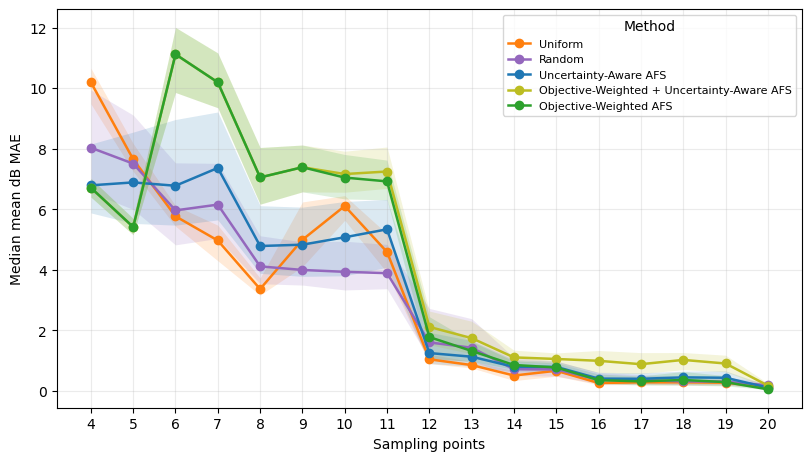

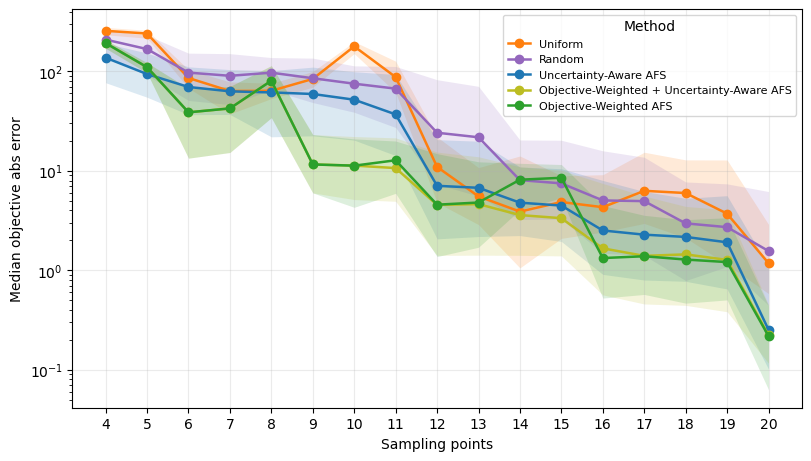

(   sample_count           method  cases  median_mean_db_mae  mean_mean_db_mae  \
 0             4  oracle_vf_error    250            6.715583          6.736461   
 1             4        owafs_bnn    250            6.715583          6.736461   
 2             4           random    250            8.035952          8.208711   
 3             4              uaw    250            6.794184          7.150945   
 4             4          uniform    250           10.200003          9.969690   
 
    q25_mean_db_mae  q75_mean_db_mae  median_objective_abs_error  \
 0         6.406729         7.024132                  192.597255   
 1         6.406729         7.024132                  192.597255   
 2         6.555675         9.942856                  208.956346   
 3         5.883141         8.159460                  137.385743   
 4         9.485070        10.665515                  256.057238   
 
    mean_objective_abs_error  q25_objective_abs_error  q75_objective_abs_error  \
 0            

In [21]:

DEPLOYABLE_OWAFS_SUFFIX = '_deployable_owafs'
DEPLOYABLE_OWAFS_METHODS = ['uniform', 'random', 'uaw', 'owafs_bnn', 'oracle_vf_error']
DEPLOYABLE_OWAFS_VF_POLICY = VF_ORDER_POLICY_ORDER_MATCHED
DEPLOYABLE_OWAFS_LABELS = {
    'uniform': 'Uniform',
    'random': 'Random',
    'uaw': 'Uncertainty-Aware AFS',
    'owafs_bnn': 'Objective-Weighted + Uncertainty-Aware AFS',
    'oracle_vf_error': 'Objective-Weighted AFS',
}
DEPLOYABLE_OWAFS_COLORS = {
    'uniform': '#ff7f0e',
    'random': '#9467bd',
    'uaw': '#1f77b4',
    'owafs_bnn': '#bcbd22',
    'oracle_vf_error': '#2ca02c',
}


def deployable_owafs_selector_config(sample_count: int) -> owafs.ObjectiveWeightedAFSConfig:
    return owafs.ObjectiveWeightedAFSConfig(
        sample_count=int(sample_count),
        initial_anchor_count=9,
        min_spacing_indices=2,
        boundary_ghz=tuple(float(x) for x in BCLF_BOUNDARY_GHZ),
    )


def deployable_owafs_vf_config() -> owafs.VFFitConfig:
    return owafs.VFFitConfig(
        n_poles_real=int(CONFIG['vf_n_poles_real']),
        n_poles_complex=int(CONFIG['vf_n_poles_complex']),
        max_iter=int(CONFIG['vf_max_iter']),
        tol=float(CONFIG['vf_tol']),
        order_policy=DEPLOYABLE_OWAFS_VF_POLICY,
    )


def select_deployable_owafs_indices(
    mean_s: np.ndarray,
    response_samples_for_case: np.ndarray,
    sample_count: int,
) -> np.ndarray:
    result = owafs.select_objective_weighted_afs_indices(
        dataset.freqs,
        mean_s,
        owafs.uncertainty_profile_from_samples(response_samples_for_case),
        n_points=int(sample_count),
        config=deployable_owafs_selector_config(int(sample_count)),
        vf_config=deployable_owafs_vf_config(),
    )
    return result.indices


def add_deployable_metadata(row: dict, *, method: str, indices: np.ndarray) -> dict:
    out = add_order_metadata(row, indices, DEPLOYABLE_OWAFS_VF_POLICY)
    out['experiment'] = 'deployable_owafs_bnn'
    out['selector_uses_full_wave_truth'] = bool(method == 'oracle_vf_error')
    if method == 'owafs_bnn':
        out['selection_source'] = 'bnn_mean_vf_residual_plus_bnn_mc_uncertainty'
    elif method == 'oracle_vf_error':
        out['selection_source'] = 'full_wave_truth_vf_residual_upper_bound'
    else:
        out['selection_source'] = method
    return out


def run_deployable_owafs_sampling_count_sweep(config: dict, states: dict[int, dict]) -> pd.DataFrame:
    rows: list[dict] = []
    vf_config = deployable_owafs_vf_config()
    _ = vf_config

    for seed in config['seeds']:
        state = states[int(seed)]
        surrogate = state['surrogate']
        eval_idx = state['eval_idx']
        mean_response, response_samples = surrogate.predict_s_params(
            dataset,
            eval_idx,
            mc_samples=int(config['mc_samples']),
            return_samples=True,
        )

        for local_pos, sample_idx in enumerate(eval_idx):
            sample_idx = int(sample_idx)
            true_s = dataset.s_params[sample_idx]
            true_obj = objective_value(true_s)
            profile = uncertainty_profile_from_samples(response_samples, local_pos)
            bnn_mean_s = mean_response[local_pos]
            bnn_samples_for_case = response_samples[:, local_pos, :, :, :]
            oracle_index_cache = (
                select_oracle_vf_error_index_path(
                    true_s,
                    SAMPLING_NUMS,
                    vf_order_policy=DEPLOYABLE_OWAFS_VF_POLICY,
                )
                if 'oracle_vf_error' in DEPLOYABLE_OWAFS_METHODS
                else {}
            )

            for sample_count in SAMPLING_NUMS:
                for method in DEPLOYABLE_OWAFS_METHODS:
                    if method == 'oracle_vf_error':
                        indices = oracle_index_cache[int(sample_count)]
                    elif method == 'owafs_bnn':
                        indices = select_deployable_owafs_indices(bnn_mean_s, bnn_samples_for_case, int(sample_count))
                    else:
                        indices = select_frequency_indices(
                            method,
                            profile,
                            int(sample_count),
                            sweep_method_rng(int(seed), sample_idx, method, int(sample_count)),
                        )

                    fit_t0 = time.perf_counter()
                    try:
                        pred_s = reconstruct_sparams(
                            true_s,
                            indices,
                            vf_order_policy=DEPLOYABLE_OWAFS_VF_POLICY,
                        )
                        fit_sec = float(time.perf_counter() - fit_t0)
                        row = successful_reconstruction_row(
                            state=state,
                            sample_idx=sample_idx,
                            sample_count=int(sample_count),
                            method=method,
                            indices=indices,
                            true_s=true_s,
                            pred_s=pred_s,
                            true_obj=true_obj,
                            fit_sec=fit_sec,
                        )
                        rows.append(add_deployable_metadata(row, method=method, indices=indices))
                    except Exception as exc:
                        fit_sec = float(time.perf_counter() - fit_t0)
                        row = empty_reconstruction_row(
                            state=state,
                            sample_idx=sample_idx,
                            sample_count=int(sample_count),
                            method=method,
                            indices=indices,
                            true_obj=true_obj,
                            fit_sec=fit_sec,
                            error=exc,
                        )
                        rows.append(add_deployable_metadata(row, method=method, indices=indices))

    out = pd.DataFrame(rows)
    out.to_csv(OUTPUT_DIR / 'sample_count_sweep_rows_deployable_owafs.csv', index=False)
    out[out['sample_count'] == max(SAMPLING_NUMS)].copy().to_csv(
        OUTPUT_DIR / 'reconstruction_rows_deployable_owafs.csv',
        index=False,
    )
    return out


def build_deployable_owafs_rank_tables(summary: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    rank_rows: list[dict] = []
    for metric_name, spec in METRIC_SPECS.items():
        col = spec['median_col']
        for sample_count, group in summary.groupby('sample_count'):
            ranked = group.set_index('method')[col].rank(method='min', ascending=True)
            for method, rank in ranked.items():
                value = group.loc[group['method'] == method, col].iloc[0]
                rank_rows.append({
                    'metric': metric_name,
                    'sample_count': int(sample_count),
                    'regime': sampling_regime(int(sample_count)),
                    'method': str(method),
                    'rank': float(rank),
                    'value': float(value),
                    'vf_order_policy': DEPLOYABLE_OWAFS_VF_POLICY,
                })
    rank_detail = pd.DataFrame(rank_rows).sort_values(['metric', 'sample_count', 'rank', 'method'])
    rank_summary = (
        rank_detail.groupby(['metric', 'method'], as_index=False)
        .agg(
            mean_rank=('rank', 'mean'),
            median_rank=('rank', 'median'),
            best_count=('rank', lambda x: int((x == 1).sum())),
            worst_rank=('rank', 'max'),
        )
        .sort_values(['metric', 'mean_rank', 'method'])
    )
    rank_summary['vf_order_policy'] = DEPLOYABLE_OWAFS_VF_POLICY
    rank_detail.to_csv(OUTPUT_DIR / 'sample_count_rank_detail_deployable_owafs.csv', index=False)
    rank_summary.to_csv(OUTPUT_DIR / 'sample_count_rank_summary_deployable_owafs.csv', index=False)
    return rank_detail, rank_summary


def plot_deployable_owafs_metric(summary: pd.DataFrame, *, metric: str, ylabel: str, path: Path) -> Path:
    fig, ax = plt.subplots(figsize=(8, 4.5), constrained_layout=True)
    q25 = f'q25_{metric}'
    q75 = f'q75_{metric}'
    median = f'median_{metric}'
    positive_values: list[float] = []
    for method in DEPLOYABLE_OWAFS_METHODS:
        sub = summary[summary['method'] == method].sort_values('sample_count')
        if sub.empty:
            continue
        x = sub['sample_count'].to_numpy(dtype=float)
        y = sub[median].to_numpy(dtype=float)
        ax.plot(
            x,
            y,
            marker='o',
            linewidth=1.8,
            label=DEPLOYABLE_OWAFS_LABELS[method],
            color=DEPLOYABLE_OWAFS_COLORS[method],
        )
        if q25 in sub.columns and q75 in sub.columns and len(sub) >= 2:
            ax.fill_between(
                x,
                sub[q25].to_numpy(dtype=float),
                sub[q75].to_numpy(dtype=float),
                alpha=0.16,
                color=DEPLOYABLE_OWAFS_COLORS[method],
                linewidth=0,
            )
        positive_values.extend([float(v) for v in y if np.isfinite(v) and v > 0.0])
    if metric == 'objective_abs_error' and positive_values:
        ratio = max(positive_values) / max(min(positive_values), 1e-12)
        if ratio >= 100.0:
            ax.set_yscale('log')
    ax.set_xlabel('Sampling points')
    ax.set_ylabel(ylabel)
    ax.set_xticks(SAMPLING_NUMS)
    ax.grid(alpha=0.25)
    ax.legend(title='Method', fontsize=8)
    fig.savefig(path, dpi=160)
    plt.show()
    plt.close(fig)
    return path


def write_deployable_owafs_plots(summary: pd.DataFrame) -> list[str]:
    PLOT_DIR.mkdir(parents=True, exist_ok=True)
    saved = [
        plot_deployable_owafs_metric(
            summary,
            metric='mean_db_mae',
            ylabel='Median mean dB MAE',
            path=PLOT_DIR / 'deployable_owafs_sample_count_vs_mean_db_mae.png',
        ),
        plot_deployable_owafs_metric(
            summary,
            metric='objective_abs_error',
            ylabel='Median objective abs error',
            path=PLOT_DIR / 'deployable_owafs_sample_count_vs_objective_abs_error.png',
        ),
    ]
    return [relative(path) for path in saved]


def build_deployable_owafs_acceptance_checks(
    rows: pd.DataFrame,
    summary: pd.DataFrame,
    plot_paths: list[str],
) -> pd.DataFrame:
    metric_cols = [
        's11_db_mae', 's11_db_rmse', 's11_db_max_error',
        's21_db_mae', 's21_db_rmse', 's21_db_max_error',
        'mean_db_mae', 'objective_abs_error', 'true_objective', 'pred_objective',
    ]
    ok = rows[rows['status'] == 'ok'].copy()
    expected_rows = int(len(SAMPLING_NUMS) * len(DEPLOYABLE_OWAFS_METHODS) * sum(len(state['eval_idx']) for state in model_states.values()))
    expected_pairs = {(int(n), method) for n in SAMPLING_NUMS for method in DEPLOYABLE_OWAFS_METHODS}
    observed_pairs = {(int(row.sample_count), str(row.method)) for row in summary.itertuples()}
    owafs_rows = rows[rows['method'] == 'owafs_bnn']
    oracle_rows = rows[rows['method'] == 'oracle_vf_error']
    required_csvs = [
        OUTPUT_DIR / 'sample_count_sweep_rows_deployable_owafs.csv',
        OUTPUT_DIR / 'sample_count_sweep_summary_deployable_owafs.csv',
        OUTPUT_DIR / 'sample_count_rank_summary_deployable_owafs.csv',
        OUTPUT_DIR / 'reconstruction_rows_deployable_owafs.csv',
    ]
    checks = [
        {
            'check': 'deployable_owafs_all_sweep_rows_present',
            'passes': bool(len(rows) == expected_rows),
            'detail': f'{len(rows)}/{expected_rows} rows',
        },
        {
            'check': 'deployable_owafs_all_sample_count_method_pairs_summarized',
            'passes': bool(expected_pairs.issubset(observed_pairs)),
            'detail': f'{len(observed_pairs)}/{len(expected_pairs)} summarized pairs',
        },
        {
            'check': 'deployable_owafs_bnn_included_without_truth_selection',
            'passes': bool(not owafs_rows.empty and not owafs_rows['selector_uses_full_wave_truth'].astype(bool).any()),
            'detail': 'Objective-Weighted + Uncertainty-Aware AFS rows use BNN proxy residual plus uncertainty',
        },
        {
            'check': 'deployable_owafs_oracle_upper_bound_retained',
            'passes': bool(not oracle_rows.empty and oracle_rows['selector_uses_full_wave_truth'].astype(bool).all()),
            'detail': 'Objective-Weighted AFS rows remain a full-truth diagnostic',
        },
        {
            'check': 'deployable_owafs_sampled_count_matches_requested_count',
            'passes': bool(len(rows) > 0 and (rows['freq_sample_size'].astype(int) == rows['sample_count'].astype(int)).all()),
            'detail': 'freq_sample_size equals sample_count for every row',
        },
        {
            'check': 'deployable_owafs_reconstructed_grid_matches_source_grid',
            'passes': bool(ok.empty or (ok['reconstructed_points'].astype(int) == dataset.n_freqs).all()),
            'detail': f'expected {dataset.n_freqs} reconstructed points for successful rows',
        },
        {
            'check': 'deployable_owafs_metrics_are_finite_for_successful_rows',
            'passes': bool(not ok.empty and np.isfinite(ok[metric_cols].to_numpy(dtype=float)).all()),
            'detail': ', '.join(metric_cols),
        },
        {
            'check': 'deployable_owafs_artifacts_written',
            'passes': bool(all(path.exists() for path in required_csvs) and all((REPO_ROOT / path).exists() for path in plot_paths)),
            'detail': f'{len(required_csvs)} CSVs and {len(plot_paths)} plots',
        },
    ]
    return pd.DataFrame(checks)


deployable_owafs_rows_df = run_deployable_owafs_sampling_count_sweep(CONFIG, model_states)
deployable_owafs_summary_df, deployable_owafs_paired_df = summarize_sweep_to_files(
    deployable_owafs_rows_df,
    DEPLOYABLE_OWAFS_SUFFIX,
)
deployable_owafs_rank_detail_df, deployable_owafs_rank_summary_df = build_deployable_owafs_rank_tables(
    deployable_owafs_summary_df,
)
deployable_owafs_plot_paths = write_deployable_owafs_plots(deployable_owafs_summary_df)
deployable_owafs_acceptance_df = build_deployable_owafs_acceptance_checks(
    deployable_owafs_rows_df,
    deployable_owafs_summary_df,
    deployable_owafs_plot_paths,
)
deployable_owafs_acceptance_df.to_csv(OUTPUT_DIR / 'acceptance_checks_deployable_owafs.csv', index=False)
assert deployable_owafs_acceptance_df['passes'].all(), deployable_owafs_acceptance_df
deployable_owafs_summary_df.head(), deployable_owafs_rank_summary_df


## Section 6.5 - Paper-Facing IEEE Figure Export

This cell creates the article-ready AFS sweep figure. The exporter uses deterministic content hints to choose an IEEE layout; this figure is exported as double-column because it has two panels, four methods, dense sampling-count ticks, and a shared legend.

In [22]:

PAPER_FIGURE_ID = 'uaw_afs_sampling_sweep_order_matched'
PAPER_METHOD_ORDER = ['uniform', 'random', 'uaw', 'oracle_vf_error']
PAPER_METHOD_LABELS = {
    'uniform': 'Uniform',
    'random': 'Random',
    'uaw': 'Uncertainty-Aware AFS',
    'oracle_vf_error': 'Objective-Weighted AFS',
}
PAPER_METHOD_COLORS = {
    'uniform': '#ff7f0e',
    'random': '#9467bd',
    'uaw': '#1f77b4',
    'oracle_vf_error': '#2ca02c',
}


def build_uaw_afs_sampling_sweep_paper_figure(width_in: float, height_in: float, layout: str):
    fig, axes = plt.subplots(1, 2, figsize=(width_in, height_in), constrained_layout=False)
    fig.subplots_adjust(left=0.07, right=0.995, bottom=0.20, top=0.80, wspace=0.32)
    metric_specs = [
        ('mean_db_mae', 'Median mean dB MAE', 'Mean dB MAE'),
        ('objective_abs_error', 'Median objective abs. error', 'Objective abs. error'),
    ]
    handles = []
    labels = []

    for panel_idx, (ax, (metric, title, ylabel)) in enumerate(zip(axes, metric_specs)):
        median = f'median_{metric}'
        q25 = f'q25_{metric}'
        q75 = f'q75_{metric}'
        for method in PAPER_METHOD_ORDER:
            sub = order_matched_summary_df[order_matched_summary_df['method'] == method].sort_values('sample_count')
            x = sub['sample_count'].to_numpy(dtype=float)
            y = sub[median].to_numpy(dtype=float)
            line = ax.plot(
                x,
                y,
                marker='o',
                markersize=3.0,
                linewidth=1.4,
                color=PAPER_METHOD_COLORS[method],
                label=PAPER_METHOD_LABELS[method],
            )[0]
            if q25 in sub.columns and q75 in sub.columns:
                ax.fill_between(
                    x,
                    sub[q25].to_numpy(dtype=float),
                    sub[q75].to_numpy(dtype=float),
                    color=PAPER_METHOD_COLORS[method],
                    alpha=0.13,
                    linewidth=0,
                )
            if panel_idx == 0:
                handles.append(line)
                labels.append(PAPER_METHOD_LABELS[method])

        if metric == 'objective_abs_error':
            ax.set_yscale('log')
        ax.set_title(title, pad=3)
        ax.set_xlabel('Sampling points n')
        ax.set_ylabel(ylabel)
        ax.set_xticks(list(range(4, 21, 2)))
        ax.grid(True, alpha=0.25, linewidth=0.5)
        ax.text(-0.16, 1.08, chr(ord('A') + panel_idx), transform=ax.transAxes, fontweight='bold')

    fig.legend(handles, labels, loc='upper center', ncol=4, frameon=False, bbox_to_anchor=(0.5, 0.98))
    return fig


paper_figure_exporter = PaperFigureExporter(
    PAPER_FIGURE_DIR,
    asset_dir=PAPER_ASSET_DIR,
    repo_root=REPO_ROOT,
)
paper_figure_rows = paper_figure_exporter.export(
    figure_id=PAPER_FIGURE_ID,
    build_figure=build_uaw_afs_sampling_sweep_paper_figure,
    layout='auto',
    height_in=3.05,
    preview_png=True,
    reason='multi_panel_dense_methods',
    num_panels=2,
    num_curves=len(PAPER_METHOD_ORDER),
    dense_ticks=True,
    legend_items=len(PAPER_METHOD_ORDER),
)
paper_figure_manifest_df = pd.DataFrame(paper_figure_rows)
paper_figure_paths = [row['path'] for row in paper_figure_rows] + [row['mirrored_path'] for row in paper_figure_rows if row.get('mirrored_path')]
paper_figure_manifest_df


,figure_id,layout,reason,format,width_in,height_in,dpi,path,mirrored_path
0,uaw_afs_sampling_sweep_order_matched,double,multi_panel_dense_methods,pdf,7.16,3.05,300,experiments/uaw_afs_ext_offline_reproduction/p...,docs/academic/paper/assets/uaw_afs_ext_offline_reproduc...
1,uaw_afs_sampling_sweep_order_matched,double,multi_panel_dense_methods,png,7.16,3.05,300,experiments/uaw_afs_ext_offline_reproduction/p...,docs/academic/paper/assets/uaw_afs_ext_offline_reproduc...


In [23]:

def compare_vf_order_policies(
    fixed_rank_summary: pd.DataFrame,
    matched_rank_summary: pd.DataFrame,
) -> pd.DataFrame:
    fixed = fixed_rank_summary.copy()
    fixed['vf_order_policy'] = 'fixed_20_poles_20_residues'
    matched = matched_rank_summary.copy()
    matched['vf_order_policy'] = ORDER_MATCHED_VF_POLICY
    out = pd.concat([fixed, matched], ignore_index=True)
    out = out.sort_values(['metric', 'method', 'vf_order_policy'])
    out.to_csv(OUTPUT_DIR / 'vf_order_policy_rank_comparison.csv', index=False)
    return out


vf_order_policy_rank_comparison_df = compare_vf_order_policies(rank_summary_df, order_matched_rank_summary_df)

policy_notes = []
for metric_name in METRIC_SPECS:
    fixed_metric = rank_summary_df[rank_summary_df['metric'] == metric_name].sort_values('mean_rank')
    matched_metric = order_matched_rank_summary_df[order_matched_rank_summary_df['metric'] == metric_name].sort_values('mean_rank')
    policy_notes.append({
        'metric': metric_name,
        'fixed_best_method': str(fixed_metric.iloc[0]['method']),
        'fixed_best_mean_rank': float(fixed_metric.iloc[0]['mean_rank']),
        'order_matched_best_method': str(matched_metric.iloc[0]['method']),
        'order_matched_best_mean_rank': float(matched_metric.iloc[0]['mean_rank']),
        'fixed_uaw_mean_rank': float(fixed_metric[fixed_metric['method'] == 'uaw']['mean_rank'].iloc[0]),
        'order_matched_uaw_mean_rank': float(matched_metric[matched_metric['method'] == 'uaw']['mean_rank'].iloc[0]),
        'fixed_oracle_mean_rank': float(fixed_metric[fixed_metric['method'] == 'oracle_vf_error']['mean_rank'].iloc[0]),
        'order_matched_oracle_mean_rank': float(matched_metric[matched_metric['method'] == 'oracle_vf_error']['mean_rank'].iloc[0]),
    })

vf_order_policy_takeaways_df = pd.DataFrame(policy_notes)
vf_order_policy_takeaways_df.to_csv(OUTPUT_DIR / 'vf_order_policy_takeaways.csv', index=False)
vf_order_policy_takeaways_df


,metric,fixed_best_method,fixed_best_mean_rank,order_matched_best_method,order_matched_best_mean_rank,fixed_uaw_mean_rank,order_matched_uaw_mean_rank,fixed_oracle_mean_rank,order_matched_oracle_mean_rank
0,mean_db_mae,uniform,1.705882,uniform,1.705882,2.941176,2.941176,2.882353,2.941176
1,objective_abs_error,oracle_vf_error,1.294118,oracle_vf_error,1.588235,2.705882,1.764706,1.294118,1.588235


In [24]:

def build_order_matched_acceptance_checks(rows: pd.DataFrame, summary: pd.DataFrame, plot_paths: list[str]) -> pd.DataFrame:
    metric_cols = [
        's11_db_mae', 's11_db_rmse', 's11_db_max_error',
        's21_db_mae', 's21_db_rmse', 's21_db_max_error',
        'mean_db_mae', 'objective_abs_error', 'true_objective', 'pred_objective',
    ]
    ok = rows[rows['status'] == 'ok'].copy()
    expected_rows = int(len(SAMPLING_NUMS) * len(ORDER_MATCHED_METHODS) * sum(len(state['eval_idx']) for state in model_states.values()))
    expected_pairs = {(int(n), method) for n in SAMPLING_NUMS for method in ORDER_MATCHED_METHODS}
    observed_pairs = {(int(row.sample_count), str(row.method)) for row in summary.itertuples()}
    requested_counts_match = bool(len(rows) > 0 and (rows['freq_sample_size'].astype(int) == rows['sample_count'].astype(int)).all())
    reconstructed_points_match = bool(ok.empty or (ok['reconstructed_points'].astype(int) == dataset.n_freqs).all())
    expected_actual_poles = rows['sample_count'].astype(int) // 2
    order_budget_ok = bool(
        len(rows) > 0
        and (rows['vf_order_policy'] == ORDER_MATCHED_VF_POLICY).all()
        and (rows['vf_actual_poles'].astype(int) == expected_actual_poles).all()
        and (rows['vf_n_poles_real'].astype(int) == (expected_actual_poles % 2)).all()
        and (rows['vf_n_poles_complex'].astype(int) == (expected_actual_poles // 2)).all()
        and (rows['vf_pole_residue_terms'].astype(int) == 2 * expected_actual_poles).all()
        and (rows['vf_pole_residue_terms'].astype(int) <= rows['sample_count'].astype(int)).all()
    )

    paper_pdf = PAPER_FIGURE_DIR / f'{PAPER_FIGURE_ID}_ieee_double.pdf'
    paper_png = PAPER_FIGURE_DIR / f'{PAPER_FIGURE_ID}_ieee_double.png'
    paper_single_pdf = PAPER_FIGURE_DIR / f'{PAPER_FIGURE_ID}_ieee_single.pdf'
    paper_single_png = PAPER_FIGURE_DIR / f'{PAPER_FIGURE_ID}_ieee_single.png'
    paper_asset_pdf = PAPER_ASSET_DIR / paper_pdf.name
    paper_asset_png = PAPER_ASSET_DIR / paper_png.name
    paper_asset_single_pdf = PAPER_ASSET_DIR / paper_single_pdf.name
    paper_asset_single_png = PAPER_ASSET_DIR / paper_single_png.name
    paper_manifest = PAPER_FIGURE_DIR / 'paper_figure_manifest.csv'
    paper_asset_manifest = PAPER_ASSET_DIR / 'paper_figure_manifest.csv'
    paper_manifest_ok = False
    if paper_manifest.exists():
        manifest_rows = pd.read_csv(paper_manifest)
        figure_rows = manifest_rows[manifest_rows['figure_id'] == PAPER_FIGURE_ID]
        paper_manifest_ok = bool(
            len(figure_rows) == 2
            and set(figure_rows['layout']) == {'double'}
            and set(figure_rows['format']) == {'pdf', 'png'}
            and set(figure_rows['reason']) == {'multi_panel_dense_methods'}
        )

    required_csvs = [
        OUTPUT_DIR / 'sample_count_sweep_rows_order_matched.csv',
        OUTPUT_DIR / 'sample_count_sweep_summary_order_matched.csv',
        OUTPUT_DIR / 'sample_count_sweep_paired_order_matched.csv',
        OUTPUT_DIR / 'sample_count_best_methods_order_matched.csv',
        OUTPUT_DIR / 'sample_count_rank_summary_order_matched.csv',
        OUTPUT_DIR / 'sample_count_delta_vs_uniform_order_matched.csv',
        OUTPUT_DIR / 'sample_count_regime_summary_order_matched.csv',
        OUTPUT_DIR / 'vf_order_policy_rank_comparison.csv',
        OUTPUT_DIR / 'vf_order_policy_takeaways.csv',
    ]

    checks = [
        {
            'check': 'order_matched_all_sweep_rows_present',
            'passes': bool(len(rows) == expected_rows),
            'detail': f'{len(rows)}/{expected_rows} rows',
        },
        {
            'check': 'order_matched_all_sample_count_method_pairs_summarized',
            'passes': bool(expected_pairs.issubset(observed_pairs)),
            'detail': f'{len(observed_pairs)}/{len(expected_pairs)} summarized pairs',
        },
        {
            'check': 'order_matched_vf_budget_policy_recorded',
            'passes': order_budget_ok,
            'detail': 'actual_poles=floor(n/2), pole+residue terms=2*actual_poles<=n',
        },
        {
            'check': 'order_matched_sampled_count_matches_requested_count',
            'passes': requested_counts_match,
            'detail': 'freq_sample_size equals sample_count for every row',
        },
        {
            'check': 'order_matched_reconstructed_grid_matches_source_grid',
            'passes': reconstructed_points_match,
            'detail': f'expected {dataset.n_freqs} reconstructed points for successful rows',
        },
        {
            'check': 'order_matched_metrics_are_finite_for_successful_rows',
            'passes': bool(not ok.empty and np.isfinite(ok[metric_cols].to_numpy(dtype=float)).all()),
            'detail': ', '.join(metric_cols),
        },
        {
            'check': 'order_matched_artifacts_written',
            'passes': bool(all(path.exists() for path in required_csvs) and all((REPO_ROOT / path).exists() for path in plot_paths)),
            'detail': f'{len(required_csvs)} CSVs and {len(plot_paths)} plots',
        },
        {
            'check': 'paper_figure_layout_selected',
            'passes': bool(
                paper_pdf.exists()
                and paper_png.exists()
                and paper_asset_pdf.exists()
                and paper_asset_png.exists()
                and paper_manifest.exists()
                and paper_asset_manifest.exists()
                and paper_manifest_ok
                and not paper_single_pdf.exists()
                and not paper_single_png.exists()
                and not paper_asset_single_pdf.exists()
                and not paper_asset_single_png.exists()
            ),
            'detail': 'auto layout selected one IEEE double-column PDF plus PNG preview and no single-column variant',
        },
    ]
    return pd.DataFrame(checks)


order_matched_acceptance_df = build_order_matched_acceptance_checks(
    order_matched_rows_df,
    order_matched_summary_df,
    order_matched_plot_paths,
)
order_matched_acceptance_df.to_csv(OUTPUT_DIR / 'acceptance_checks_order_matched.csv', index=False)
assert order_matched_acceptance_df['passes'].all(), order_matched_acceptance_df
order_matched_acceptance_df


,check,passes,detail
0,order_matched_all_sweep_rows_present,True,17000/17000 rows
1,order_matched_all_sample_count_method_pairs_su...,True,68/68 summarized pairs
2,order_matched_vf_budget_policy_recorded,True,"actual_poles=floor(n/2), pole+residue terms=2*..."
3,order_matched_sampled_count_matches_requested_...,True,freq_sample_size equals sample_count for every...
4,order_matched_reconstructed_grid_matches_sourc...,True,expected 401 reconstructed points for successf...
5,order_matched_metrics_are_finite_for_successfu...,True,"s11_db_mae, s11_db_rmse, s11_db_max_error, s21..."
6,order_matched_artifacts_written,True,9 CSVs and 4 plots
7,paper_figure_layout_selected,True,auto layout selected one IEEE double-column PD...


## Section 6 - Acceptance Checks

The smoke run checks pipeline integrity for the sweep. Full-run quality comparisons are summarized but not hard-coded as assertions, because the purpose here is to measure the accuracy curve rather than force a predetermined ordering.

In [25]:
def build_acceptance_checks(rows: pd.DataFrame, summary: pd.DataFrame, plot_paths: list[str]) -> pd.DataFrame:
    metric_cols = [
        's11_db_mae', 's11_db_rmse', 's11_db_max_error',
        's21_db_mae', 's21_db_rmse', 's21_db_max_error',
        'mean_db_mae', 'objective_abs_error', 'true_objective', 'pred_objective',
    ]
    ok = rows[rows['status'] == 'ok'].copy()
    expected_rows = int(len(SAMPLING_NUMS) * len(METHODS) * sum(len(state['eval_idx']) for state in model_states.values()))
    expected_pairs = {(int(n), method) for n in SAMPLING_NUMS for method in METHODS}
    observed_pairs = {(int(row.sample_count), str(row.method)) for row in summary.itertuples()}
    requested_counts_match = bool(len(rows) > 0 and (rows['freq_sample_size'].astype(int) == rows['sample_count'].astype(int)).all())
    reconstructed_points_match = bool(ok.empty or (ok['reconstructed_points'].astype(int) == dataset.n_freqs).all())

    checks = [
        {
            'check': 'dataset_loaded',
            'passes': bool(dataset.n_samples > 0 and dataset.n_freqs == 401 and dataset.s_params.shape[1:3] == (2, 2)),
            'detail': f'{dataset.n_samples} samples, {dataset.n_freqs} frequency points',
        },
        {
            'check': 'bnn_model_ready',
            'passes': bool(not model_cache_df.empty and set(model_cache_df['model_status']).issubset({'trained', 'loaded'})),
            'detail': '; '.join(f"seed={row.seed}:{row.model_status}" for row in model_cache_df.itertuples()),
        },
        {
            'check': 'all_sweep_rows_present',
            'passes': bool(len(rows) == expected_rows),
            'detail': f'{len(rows)}/{expected_rows} rows',
        },
        {
            'check': 'all_sample_count_method_pairs_summarized',
            'passes': bool(expected_pairs.issubset(observed_pairs)),
            'detail': f'{len(observed_pairs)}/{len(expected_pairs)} summarized pairs',
        },
        {
            'check': 'oracle_vf_error_included',
            'passes': bool('oracle_vf_error' in set(rows['method'])),
            'detail': 'offline oracle method appears in sweep rows',
        },
        {
            'check': 'sampled_count_matches_requested_count',
            'passes': requested_counts_match,
            'detail': 'freq_sample_size equals sample_count for every row',
        },
        {
            'check': 'reconstructed_grid_matches_source_grid',
            'passes': reconstructed_points_match,
            'detail': f'expected {dataset.n_freqs} reconstructed points for successful rows',
        },
        {
            'check': 'metrics_are_finite_for_successful_rows',
            'passes': bool(not ok.empty and np.isfinite(ok[metric_cols].to_numpy(dtype=float)).all()),
            'detail': ', '.join(metric_cols),
        },
        {
            'check': 'sweep_artifacts_written',
            'passes': bool(
                (OUTPUT_DIR / 'sample_count_sweep_rows.csv').exists()
                and (OUTPUT_DIR / 'sample_count_sweep_summary.csv').exists()
                and (OUTPUT_DIR / 'sample_count_sweep_paired.csv').exists()
                and all((REPO_ROOT / path).exists() for path in plot_paths)
            ),
            'detail': f'{len(plot_paths)} plots plus sweep CSVs',
        },
        {
            'check': 'enriched_analysis_artifacts_written',
            'passes': bool(
                (OUTPUT_DIR / 'sample_count_best_methods.csv').exists()
                and (OUTPUT_DIR / 'sample_count_rank_detail.csv').exists()
                and (OUTPUT_DIR / 'sample_count_rank_summary.csv').exists()
                and (OUTPUT_DIR / 'sample_count_delta_vs_uniform.csv').exists()
                and (OUTPUT_DIR / 'sample_count_regime_summary.csv').exists()
            ),
            'detail': 'best-method, rank, delta-vs-uniform, and regime CSVs',
        },
    ]
    return pd.DataFrame(checks)


acceptance_df = build_acceptance_checks(sweep_rows_df, sweep_summary_df, plot_paths)
acceptance_df.to_csv(OUTPUT_DIR / 'acceptance_checks.csv', index=False)
assert acceptance_df['passes'].all(), acceptance_df
acceptance_df

,check,passes,detail
0,dataset_loaded,True,"1369 samples, 401 frequency points"
1,bnn_model_ready,True,seed=0:loaded; seed=1:loaded; seed=2:loaded; s...
2,all_sweep_rows_present,True,17000/17000 rows
3,all_sample_count_method_pairs_summarized,True,68/68 summarized pairs
4,oracle_vf_error_included,True,offline oracle method appears in sweep rows
5,sampled_count_matches_requested_count,True,freq_sample_size equals sample_count for every...
6,reconstructed_grid_matches_source_grid,True,expected 401 reconstructed points for successf...
7,metrics_are_finite_for_successful_rows,True,"s11_db_mae, s11_db_rmse, s11_db_max_error, s21..."
8,sweep_artifacts_written,True,5 plots plus sweep CSVs
9,enriched_analysis_artifacts_written,True,"best-method, rank, delta-vs-uniform, and regim..."


In [26]:
artifact_paths = [
    OUTPUT_DIR / 'run_config.json',
    OUTPUT_DIR / 'filtered_ext_index.json',
    OUTPUT_DIR / 'bnn_model_cache.csv',
    OUTPUT_DIR / 'sample_count_sweep_rows.csv',
    OUTPUT_DIR / 'sample_count_sweep_summary.csv',
    OUTPUT_DIR / 'sample_count_sweep_paired.csv',
    OUTPUT_DIR / 'reconstruction_rows.csv',
    OUTPUT_DIR / 'summary_by_seed_method.csv',
    OUTPUT_DIR / 'summary_overall.csv',
    OUTPUT_DIR / 'paired_uaw_vs_baselines.csv',
    OUTPUT_DIR / 'acceptance_checks.csv',
    OUTPUT_DIR / 'sample_count_best_methods.csv',
    OUTPUT_DIR / 'sample_count_rank_detail.csv',
    OUTPUT_DIR / 'sample_count_rank_summary.csv',
    OUTPUT_DIR / 'sample_count_delta_vs_uniform.csv',
    OUTPUT_DIR / 'sample_count_regime_summary.csv',
    *[REPO_ROOT / path for path in plot_paths],
]
if 'order_matched_plot_paths' in globals():
    artifact_paths.extend([
        OUTPUT_DIR / 'sample_count_sweep_rows_order_matched.csv',
        OUTPUT_DIR / 'sample_count_sweep_summary_order_matched.csv',
        OUTPUT_DIR / 'sample_count_sweep_paired_order_matched.csv',
        OUTPUT_DIR / 'reconstruction_rows_order_matched.csv',
        OUTPUT_DIR / 'summary_by_seed_method_order_matched.csv',
        OUTPUT_DIR / 'summary_overall_order_matched.csv',
        OUTPUT_DIR / 'paired_uaw_vs_baselines_order_matched.csv',
        OUTPUT_DIR / 'sample_count_best_methods_order_matched.csv',
        OUTPUT_DIR / 'sample_count_rank_detail_order_matched.csv',
        OUTPUT_DIR / 'sample_count_rank_summary_order_matched.csv',
        OUTPUT_DIR / 'sample_count_delta_vs_uniform_order_matched.csv',
        OUTPUT_DIR / 'sample_count_regime_summary_order_matched.csv',
        OUTPUT_DIR / 'vf_order_policy_rank_comparison.csv',
        OUTPUT_DIR / 'vf_order_policy_takeaways.csv',
        OUTPUT_DIR / 'acceptance_checks_order_matched.csv',
        *[REPO_ROOT / path for path in order_matched_plot_paths],
    ])
if 'deployable_owafs_plot_paths' in globals():
    artifact_paths.extend([
        OUTPUT_DIR / 'sample_count_sweep_rows_deployable_owafs.csv',
        OUTPUT_DIR / 'sample_count_sweep_summary_deployable_owafs.csv',
        OUTPUT_DIR / 'sample_count_rank_detail_deployable_owafs.csv',
        OUTPUT_DIR / 'sample_count_rank_summary_deployable_owafs.csv',
        OUTPUT_DIR / 'reconstruction_rows_deployable_owafs.csv',
        OUTPUT_DIR / 'acceptance_checks_deployable_owafs.csv',
        *[REPO_ROOT / path for path in deployable_owafs_plot_paths],
    ])
if 'paper_figure_paths' in globals():
    artifact_paths.extend([
        PAPER_FIGURE_DIR / 'paper_figure_manifest.csv',
        PAPER_ASSET_DIR / 'paper_figure_manifest.csv',
        PAPER_FIGURE_DIR / f'{PAPER_FIGURE_ID}_ieee_double.pdf',
        PAPER_FIGURE_DIR / f'{PAPER_FIGURE_ID}_ieee_double.png',
        PAPER_ASSET_DIR / f'{PAPER_FIGURE_ID}_ieee_double.pdf',
        PAPER_ASSET_DIR / f'{PAPER_FIGURE_ID}_ieee_double.png',
    ])
[relative(path) for path in artifact_paths if path.exists()]


['experiments/uaw_afs_ext_offline_reproduction/run_config.json',
 'experiments/uaw_afs_ext_offline_reproduction/filtered_ext_index.json',
 'experiments/uaw_afs_ext_offline_reproduction/bnn_model_cache.csv',
 'experiments/uaw_afs_ext_offline_reproduction/sample_count_sweep_rows.csv',
 'experiments/uaw_afs_ext_offline_reproduction/sample_count_sweep_summary.csv',
 'experiments/uaw_afs_ext_offline_reproduction/sample_count_sweep_paired.csv',
 'experiments/uaw_afs_ext_offline_reproduction/reconstruction_rows.csv',
 'experiments/uaw_afs_ext_offline_reproduction/summary_by_seed_method.csv',
 'experiments/uaw_afs_ext_offline_reproduction/summary_overall.csv',
 'experiments/uaw_afs_ext_offline_reproduction/paired_uaw_vs_baselines.csv',
 'experiments/uaw_afs_ext_offline_reproduction/acceptance_checks.csv',
 'experiments/uaw_afs_ext_offline_reproduction/sample_count_best_methods.csv',
 'experiments/uaw_afs_ext_offline_reproduction/sample_count_rank_detail.csv',
 'experiments/uaw_afs_ext_offline_